In [1]:
# analysis PLOT for the line plots

import pandas as pd
import os
import sys
import numpy as np
import matplotlib.pyplot as plt


def read_AHA_csv(merged_df, device, lengths, collision_fields=['Combined_Collision'], diameters=None, conestr=''): 
    main_path = '/data_fast/Work/MS_HF_cohort/images'
    #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
      
 
    for i, length in enumerate(lengths): #, 15, 20, 25, 30, 35, 40, 45]:  #[22, 27, 32, 37, 42]: 
        for collision_field in collision_fields: #['RV_Collision', 'TV_Collision', 'PM_Collision', 'Combined_Collision']: 
            diameter = diameters[i] if diameters is not None else None
            #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
            if collision_field=='Combined_Collision':
                images_outpath=f'{main_path}/{device}{conestr}/'
                add_legend=True
            else: 
                images_outpath=f'{main_path}/{device}{conestr}/{collision_field}/'
                add_legend=False


            csv_outfile=f'{images_outpath}/sum_plots/RV_septum_polar_sum_{device}_L{length}.csv'
            #print(f'CSV outfile: {csv_outfile}')
            df= pd.read_csv(csv_outfile)
            #display(df)
            if diameter is not None: 
                label= f'{device}_L{length}_D{diameter:1.1f}_{collision_field}'
            else:     
                label= f'{device}_L{length}_{collision_field}'
                # Create formatted column
            df[label] = df.apply(lambda row: f"{row['mean']:.1f} ± {row['std']:.1f}", axis=1)
            # Subset to AHA_region and formatted column
            df = df[["AHA_region", label]]

            # Merge
            if merged_df is None:
                merged_df = df
            else:
                merged_df = pd.merge(merged_df, df, on="AHA_region", how="outer")
    return merged_df


def extract_mean_std_from_formatted(formatted_str):
    """Extract mean and std from formatted string 'mean ± std'"""
    try:
        parts = formatted_str.split(' ± ')
        mean = float(parts[0])
        std = float(parts[1])
        return mean, std
    except:
        return np.nan, np.nan
    
        under_color = "#4da6ff"
        under_color = "#66b38c"        
        under_color = "#ff9933"


def get_specs(): 
    device_colors = {
        'Micra': '#003d7a', ## '#2596be',
        'MicraTPS': '#003d7a',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#cc6600',  # '#b2182b',
        'AveirAR': '#00664f'  #  '#92c5de'
    }
    device_linestyles = {
        'Micra': '-',
        'MicraTPS': '-',
        'OtherPallete': '--',
        'AveirVR': '-.',
        'AveirAR': ':', 
        '20': '-', 
        '21': '--', 
        '22': ':', 
        '23': '.-'
    }
    device_markers = {
        'Micra': 'o',
        'MicraTPS': 'o',
        'OtherPallete': 's',
        'AveirVR': '^',
        'AveirAR': 'D', 
        20: 'o', 
        21: 's', 
        22: '^', 
        23: 'D'
    }
    init_lens = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'MicraTPS': 25.9  # If you use MicraTPS as a device name
    }
    init_diams = {
        'AveirVR': 6.5,
        'AveirAR': 6.5,
        'MicraTPS': 6.7  # If you use MicraTPS as a device name
    }
    return device_colors, device_linestyles, device_markers, init_lens, init_diams
def plot_collision_data_by_aha(merged_df, output_path=None, plot_CS=True,collision_fields=['PM_Collision', 'TV_Collision', 'RV_Collision', 'Combined_Collision']):
    """
    Plot mean and standard deviation over lengths for each AHA region and collision field
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    """
    if plot_CS:
    # Keep rows where 'AHA region' >= 20
        merged_df = merged_df[merged_df['AHA region'] >= 20]
    else:
        # Keep rows where 'AHA region' < 20
        merged_df = merged_df[merged_df['AHA region'] < 20]

    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']

    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            
            # Check if there's a diameter component (D followed by number)
            diameter = None
            collision_start_idx = 2
            
            if len(parts) > 3 and parts[2].startswith('D'):
                try:
                    diameter = float(parts[2].replace('D', ''))
                    collision_start_idx = 3
                except ValueError:
                    # If D part can't be converted to float, treat as part of collision_field
                    pass
            
            collision_field = '_'.join(parts[collision_start_idx:])
            
            # Handle device name mapping
            if device == 'Micra': 
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'diameter': diameter,
                'collision_field': collision_field
            })
    # for col in columns:
    #     parts = col.split('_')
    #     if len(parts) >= 3:
    #         device = parts[0]
    #         length = parts[1].replace('L', '')
    #         collision_field = '_'.join(parts[2:])
    #         if device=='Micra': 
    #             device = 'MicraTPS'

    #         data_info.append({
    #             'column': col,
    #             'device': device,
    #             'length': float(length),
    #             'collision_field': collision_field
    #         })
    
    #print(data_info)
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)

    # Get unique values
    devices = sorted(info_df['device'].unique())
    #collision_fields = sorted(info_df['collision_field'].unique())

    aha_regions = sorted(merged_df['AHA region'].unique())
    
    # Colors for devices
    colors = {'AveirVR': 'red', 'AveirAR': 'blue', 'Micra': 'green'}
    
    # Create plots for each collision field
    for collision_field in collision_fields: # #collision_fields:
        # First pass: collect all data to determine global y-axis limits
        all_means = []
        all_stds = []
        n_regions = len(aha_regions)
        for aha_region in aha_regions:
            if plot_CS and aha_region<20: 
                # Only plot for AHA regions 20()
                continue
            elif not plot_CS and aha_region>=20: 
                continue
                

            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                for col in device_cols:
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            all_means.append(mean)
                            all_stds.append(std)
        
        # Calculate global y-axis limits
        if all_means and all_stds:
            all_means = np.array(all_means)
            all_stds = np.array(all_stds)
            y_min = np.min(all_means - all_stds)
            y_max = np.max(all_means + all_stds)
            # Add some padding
            y_range = y_max - y_min
            y_min = max(0, y_min - 0.05 * y_range)  # Don't go below 0
            y_max = y_max + 0.05 * y_range
        else:
            y_min, y_max = 0, 100  # Default range
        
        n_regions = len(aha_regions)
        n_rows = 1  # Single row
        n_cols = n_regions  # One column per AHA region
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 5))
        # Handle different subplot configurations
        if n_regions == 1:
            # Single subplot case
            axes = [axes]
        else:  
            # Multiple subplots case
            if isinstance(axes, np.ndarray):
                if axes.ndim == 1:
                    # Single row or single column of subplots
                    axes = axes.tolist()
                else:
                    # Multiple rows and columns
                    axes = axes.flatten().tolist()
            else:
                # This shouldn't happen with n_regions > 1, but just in case
                axes = [axes]
        offset=10
        xoffset=0
        if collision_field.startswith('Combined_Collision'): 
            title_str='Combined collision risk'
            offset=-20 # point up = -10, point down = +10 for init_len 
            xoffset=0
        elif collision_field.startswith('RV_Collision'): 
            title_str='RV endocardium collision risk'
            if not plot_CS: 
                offset=-15
            else: 
                xoffset=-5 
                print('Change xoffset for RV collision for plotCS')
        elif collision_field.startswith('TV_Collision'): 
            title_str='Tricuspid valve structures collision risk'
        elif collision_field.startswith('PM_Collision'): 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str=collision_field
        print(f'Y OFFSET: {offset}')

        if plot_CS: 
            fig.suptitle(f'{title_str} - Mean ± SD by Length and LBBAP region', fontsize=16, y=0.98, fontweight='bold')
        else: 
            fig.suptitle(f'{title_str} - Mean ± SD by Length and AHA Region', fontsize=18, y=0.98, fontweight='bold')
        print(axes[0])
        for i, aha_region in enumerate(aha_regions):
            if aha_region==2 and collision_field.startswith('Combined_Collision'): 
                xoffset=5

            ax = axes[i] if n_regions > 1 else axes[0]
            
            # Get data for this AHA region
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                # Filter columns for this device and collision field
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()

                if not device_cols:
                    continue
                
                # Extract lengths and values
                lengths = []
                means = []
                stds = []
                diameters =[]
                for col in device_cols:
                    # Get length from column name
                    length = info_df[info_df['column'] == col]['length'].iloc[0]
                    diameter = info_df[info_df['column'] == col]['diameter'].iloc[0]
                    # Get formatted value
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            lengths.append(length)
                            if diameter is not None: 
                                diameters.append(diameter)
                            means.append(mean)
                            stds.append(std)

                
                if lengths:  # Only plot if we have data
                    lengths = np.array(lengths)                    
                    means = np.array(means)
                    stds = np.array(stds)
                    if diameter is not None: 
                        diameters = np.array(diameters)
                    
                    # Sort by length
                    sort_idx = np.argsort(lengths)
                    lengths = lengths[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    # Plot mean line with error bars
                    color = colors.get(device, 'black')
                    #ax.plot(lengths, means, marker='o', color=color, label=device, linewidth=2)
                    device_colors, device_linestyles, device_markers, init_lens, init_diams=get_specs()
                    
                    

                    if diameter is not None: 
                        ax.plot(diameters, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(diameters, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                        # Add arrow at init_len
                        init_len = init_diams.get(device)
                        if init_len is not None and init_len in diameters:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                y_offset=offset
                                if device=='AveirAR': 
                                    y_offset=offset*1.5
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len+xoffset, y_val +y_offset),  # Adjust offset as needed
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), shrink=0.05, width=2),
                                    ha='center', color=device_colors.get(device, '#000000'), fontsize=12
                                )
                    else: 
                        ax.plot(lengths, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(lengths, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                                    
                        # Add arrow at init_len
                        init_len = init_lens.get(device)
                        if init_len is not None and init_len in lengths:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                y_offset=offset
                                if device=='AveirAR': 
                                    if offset>0: 
                                        y_offset=offset*1.5                                
                                    elif collision_field=='Combined_Collision': 
                                        if aha_region==14 or aha_region==3:
                                            y_offset=offset+5
                                            xoffset=0
                                    elif collision_field=='RV_Collision': 
                                        if aha_region==14: 
                                            y_offset=offset-10

                                
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len+xoffset, y_val + y_offset),  # Adjust offset as needed
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), shrink=0.05, width=2),
                                    ha='center', #color=device_colors.get(device, '#000000'), fontsize=10
                                    color='#000000', fontsize=12
                                )
            if plot_CS and aha_region==20: 
                ax.set_title('Left Bundle', color="#FF4DFF", fontsize=14)
            elif plot_CS and aha_region==21: 
                ax.set_title('Anterior Branch', color='#cc6600', fontsize=14)
            elif plot_CS and aha_region==22: 
                ax.set_title('Posterior Branch', color="#003d7a", fontsize=14)
            elif plot_CS and aha_region==23: 
                ax.set_title('Septal Branch', color="#00664f", fontsize=14)

            else: 
                ax.set_title(f'AHA Region {aha_region}', fontsize=16)
            if diameter is not None: 
                ax.set_xlabel('Diameters')
            else: 
                ax.set_xlabel('Length (mm)', fontsize=14)
            ax.set_ylabel('Collision (%)', fontsize=14)
            ax.set_yticks([0, 25, 50, 75, 100])
            ax.grid(True, alpha=0.3)
            if i == 0: # Only add legend in first plot
                ax.legend(fontsize=14, loc="upper left")
            #ax.axhline(y=50, color='r', linestyle='--', linewidth=2, label="50%% risk of collision")
            # Set the same y-axis limits for all subplots
            ax.set_ylim(0, 100)
        
        # Hide empty subplots
        for i in range(n_regions, len(axes)):
            axes[i].set_visible(False)
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            if plot_CS: 
                plt.savefig(f'{output_path}/{collision_field}_by_LBBAP_region.png', 
                       dpi=300, bbox_inches='tight')
                print(f'{output_path}/{collision_field}_by_LBBAP_region.png')
            else: 
                plt.savefig(f'{output_path}/{collision_field}_by_AHA_region.png', 
                        dpi=300, bbox_inches='tight')
                print(f'{output_path}/{collision_field}_by_AHA_region.png')
        
        plt.show()

def create_summary_table(merged_df, output_path=None):
    """Create summary statistics table"""
    # Extract numeric data from formatted strings
    numeric_data = {}
    
    for col in merged_df.columns:
        if col != 'AHA region':
            means = []
            stds = []
            for val in merged_df[col]:
                if pd.notna(val):
                    mean, std = extract_mean_std_from_formatted(val)
                    means.append(mean)
                    stds.append(std)
            
            numeric_data[col] = {
                'mean_avg': np.nanmean(means),
                'mean_std': np.nanstd(means),
                'std_avg': np.nanmean(stds),
                'std_std': np.nanstd(stds)
            }
    
    summary_df = pd.DataFrame(numeric_data).T
    
    if output_path:
        summary_df.to_csv(f'{output_path}/summary_statistics.csv')
    
    return summary_df
def plot_collision_data_regions_as_lines(merged_df, output_path=None, plot_CS=True, collision_fields = ['PM_Collision', 'TV_Collision', 'RV_Collision', 'Combined_Collision']):
    """
    Plot mean and standard deviation over lengths with each AHA region as a separate line
    for each device and collision field combination
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    plot_CS: Boolean to determine if plotting CS regions (>=20) or AHA regions (<20)
    """
    if plot_CS:
        # Keep rows where 'AHA region' >= 20
        merged_df = merged_df[merged_df['AHA region'] >= 20]
    else:
        # Keep rows where 'AHA region' < 20
        merged_df = merged_df[merged_df['AHA region'] < 20]

    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']

    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            
            # Check if there's a diameter component (D followed by number)
            diameter = None
            collision_start_idx = 2
            
            if len(parts) > 3 and parts[2].startswith('D'):
                try:
                    diameter = float(parts[2].replace('D', ''))
                    collision_start_idx = 3
                except ValueError:
                    # If D part can't be converted to float, treat as part of collision_field
                    pass
            
            collision_field = '_'.join(parts[collision_start_idx:])
            
            # Handle device name mapping
            if device == 'Micra': 
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'diameter': diameter,
                'collision_field': collision_field
            })
    
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)

    # Get unique values
    devices = sorted(info_df['device'].unique())
    
    aha_regions = sorted(merged_df['AHA region'].unique())
    
    # Get device specifications
    device_colors, device_linestyles, device_markers, init_lens, init_diams = get_specs()
    
    # Define region colors and styles
    if plot_CS:
        region_colors = {
            20: "#FF4DFF",  # Left Bundle - magenta
            21: '#cc6600',  # Anterior Branch - orange
            22: "#003d7a",  # Posterior Branch - dark blue
            23: "#00664f"   # Septal Branch - dark green
        }
        region_names = {
            20: 'Left Bundle Branch',
            21: 'Left Anterior Fascicle', 
            22: 'Left Posterior Fascicle',
            23: 'Left Septal Fascicle'
        }
        
    else:
        # Generate colors for AHA regions
        import matplotlib.cm as cm
        cmap = cm.get_cmap('tab10')
        region_colors = {region: cmap(i/len(aha_regions)) for i, region in enumerate(aha_regions)}
        region_names = {region: f'AHA Region {region}' for region in aha_regions}
    
    # Create plots for each collision field and device combination
    for collision_field in collision_fields:
        # Get title string
        if collision_field.startswith('Combined_Collision'): 
            title_str = 'Combined collision risk'
        elif collision_field.startswith('RV_Collision'): 
            title_str = 'RV endocardium collision risk'
        elif collision_field.startswith('TV_Collision'): 
            title_str = 'Tricuspid valve structures collision risk'
        elif collision_field.startswith('PM_Collision'): 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str = collision_field
            
        # Get devices that have data for this collision field
        available_devices = info_df[info_df['collision_field'] == collision_field]['device'].unique()
        n_devices = len(available_devices)
        
        if n_devices == 0:
            continue
            
        # Create subplots - one per device
        fig, axes = plt.subplots(1, n_devices, figsize=(5*n_devices, 5))
        
        # Handle single device case
        if n_devices == 1:
            axes = [axes]
        
        # Set main title
        region_type = "LBBAP region" if plot_CS else "AHA Region"
        fig.suptitle(f'{title_str} - Mean ± SD by Length and {region_type}', fontsize=16, y=0.98, fontweight='bold')
        
        for device_idx, device in enumerate(available_devices):
            ax = axes[device_idx]
            
            # Get columns for this device and collision field
            device_cols_info = info_df[
                (info_df['device'] == device) & 
                (info_df['collision_field'] == collision_field)
            ]
            
            if len(device_cols_info) == 0:
                continue
                
            # Determine if we're plotting by diameter or length
            has_diameter = device_cols_info['diameter'].notna().any()
            x_axis = 'diameter' if has_diameter else 'length'
            x_label = 'Diameter (mm)' if has_diameter else 'Length (mm)'
            
            # Plot each region as a separate line
            for aha_region in aha_regions:
                region_data = merged_df[merged_df['AHA region'] == aha_region]
                marker=device_markers.get(aha_region, 'o')
                
                if len(region_data) == 0:
                    continue
                
                # Extract data for this region
                x_values = []
                means = []
                stds = []
                
                for _, col_info in device_cols_info.iterrows():
                    col = col_info['column']
                    x_val = col_info[x_axis] if has_diameter else col_info['length']
                    
                    # Get formatted value
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            x_values.append(x_val)
                            means.append(mean)
                            stds.append(std)
                
                if x_values:  # Only plot if we have data
                    x_values = np.array(x_values)
                    means = np.array(means)
                    stds = np.array(stds)
                    
                    # Sort by x values
                    sort_idx = np.argsort(x_values)
                    x_values = x_values[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    # Plot line with error bars
                    region_color = region_colors.get(aha_region, 'black')
                    region_name = region_names.get(aha_region, f'Region {aha_region}')
                    if device=='AveirVR': 
                        ax.plot(x_values, means, label=region_name, linewidth=2, 
                           color=region_color, marker=marker, markersize=6)
                    else: 
                        ax.plot(x_values, means, linewidth=2, 
                           color=region_color, marker=marker, markersize=6)
                    ax.fill_between(x_values, means - stds, means + stds, 
                                   color=region_color, alpha=0.2)
            
            # Customize subplot
            ax.set_title(f'{device}', fontsize=14)
            ax.set_xlabel(x_label, fontsize=12)
            ax.set_ylabel('Collision (%)', fontsize=12)
            ax.set_yticks([0, 25, 50, 75, 100])
            ax.set_ylim(0, 100)
            ax.grid(True, alpha=0.3)
            
            plot_fig=False
            # Add legend
            if device=='AveirVR' and collision_field=='Combined_Collision' and plot_fig:
                #ax.legend(fontsize=12, loc="upper left")
                # ax.legend(
                #     fontsize=12,
                #     loc='upper left',
                #     bbox_to_anchor=(1.02, 1),   # push outside the axes
                #     borderaxespad=0
                # )
                # Get handles/labels only from the last subplot
                handles, labels = ax.get_legend_handles_labels()

                fig.legend(
                    handles, labels,
                    loc="lower center",   # across the full figure
                    ncol=4,               # arrange in columns
                    frameon=True,
                    bbox_to_anchor=(0.5, -0.1),
                    fontsize=12
                )
            # Add initial length/diameter annotation if applicable
            init_val = init_diams.get(device) if has_diameter else init_lens.get(device)
            if init_val is not None:
                ax.axvline(x=init_val, color=device_colors.get(device, '#000000'), 
                          linestyle='--', alpha=0.7, linewidth=1)
                if collision_field=='Combined_Collision':
                    y_val=25
                else: 
                    y_val=95
                ax.text(init_val, y_val, f'Initial\n{x_axis}', ha='center', va='top',
                       color=device_colors.get(device, '#000000'), fontsize=12,
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            region_suffix = "LBBAP_regions" if plot_CS else "AHA_regions"
            filename = f'{output_path}/{collision_field}_regions_as_lines_{region_suffix}.png'
            plt.savefig(filename, dpi=300, bbox_inches='tight')
            print(f'Saved: {filename}')
        
        plt.show()


# Helper function to extract mean and std from formatted string
def extract_mean_std_from_formatted(formatted_val):
    """
    Extract mean and standard deviation from a formatted string like "45.2 ± 12.3"
    """
    try:
        if isinstance(formatted_val, str) and '±' in formatted_val:
            parts = formatted_val.split('±')
            mean = float(parts[0].strip())
            std = float(parts[1].strip())
            return mean, std
        else:
            # If it's just a number, assume std = 0
            mean = float(formatted_val)
            return mean, 0.0
    except (ValueError, AttributeError, IndexError):
        return np.nan, np.nan



AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_RV_Collision_Cone,13.1 ± 15.0,7.2 ± 9.3,38.3 ± 31.5,29.9 ± 25.0,53.9 ± 27.6,1.4 ± 4.2,16.5 ± 23.4,17.1 ± 18.8,26.1 ± 26.4
Micra_L15_RV_Collision_Cone,2.2 ± 5.0,4.4 ± 7.4,17.5 ± 26.7,13.7 ± 18.0,45.7 ± 22.8,0.1 ± 1.2,6.0 ± 14.2,4.7 ± 9.3,5.3 ± 11.9
Micra_L20_RV_Collision_Cone,3.9 ± 6.3,5.1 ± 7.5,25.3 ± 30.9,20.0 ± 21.2,50.7 ± 24.3,0.1 ± 1.2,8.7 ± 18.1,8.1 ± 11.9,13.9 ± 20.4
Micra_L25_RV_Collision_Cone,10.5 ± 12.6,6.2 ± 8.4,35.8 ± 32.0,28.3 ± 24.4,53.7 ± 27.2,0.5 ± 2.5,14.6 ± 22.8,15.6 ± 17.7,24.3 ± 26.1
Micra_L30_RV_Collision_Cone,23.6 ± 20.7,10.2 ± 11.3,48.4 ± 30.3,38.0 ± 25.9,54.9 ± 29.8,7.2 ± 12.0,26.5 ± 25.6,27.1 ± 22.6,37.2 ± 26.7
Micra_L35_RV_Collision_Cone,41.3 ± 23.2,15.4 ± 14.7,63.2 ± 25.7,49.0 ± 24.4,56.8 ± 32.1,17.2 ± 16.1,48.4 ± 23.1,42.3 ± 22.5,51.8 ± 24.5
Micra_L40_RV_Collision_Cone,61.7 ± 24.7,27.2 ± 16.4,76.7 ± 22.5,70.1 ± 15.6,57.3 ± 33.5,41.7 ± 18.2,70.2 ± 20.5,70.3 ± 12.5,75.1 ± 15.1
Micra_L45_RV_Collision_Cone,74.7 ± 20.7,47.6 ± 18.5,88.9 ± 20.7,81.5 ± 14.4,57.4 ± 34.6,75.1 ± 14.9,91.2 ± 13.2,85.5 ± 11.3,90.7 ± 11.5
AveirAR_L32.2_RV_Collision_Cone,31.1 ± 22.3,13.2 ± 13.1,55.5 ± 29.4,43.3 ± 25.8,57.3 ± 30.3,10.6 ± 14.3,35.3 ± 26.2,34.4 ± 23.8,43.8 ± 26.4
AveirAR_L15_RV_Collision_Cone,2.9 ± 5.4,4.8 ± 8.0,18.6 ± 27.8,14.9 ± 19.7,48.2 ± 23.3,0.3 ± 1.6,6.5 ± 15.5,5.0 ± 9.8,5.6 ± 12.4


Y OFFSET: -15
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/RV_Collision_Cone_by_AHA_region.png


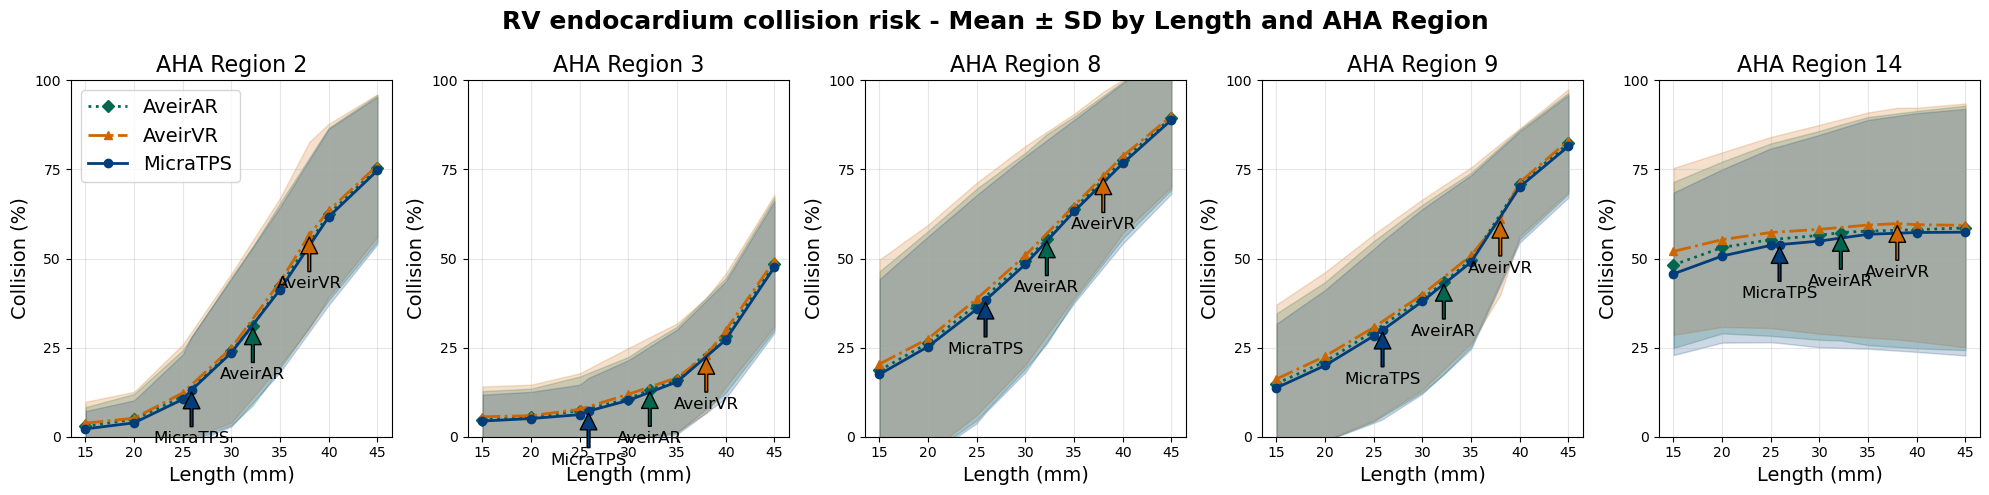

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_RV_Collision_Cone,20.3 ± 17.6,11.8 ± 13.7,47.3 ± 32.6,36.5 ± 28.7,66.3 ± 21.4,4.2 ± 8.7,22.5 ± 27.3,22.2 ± 22.5,31.7 ± 28.5
Micra_L15_RV_Collision_Cone,7.4 ± 8.1,7.6 ± 11.0,23.4 ± 32.1,17.4 ± 22.7,60.1 ± 20.0,1.0 ± 3.7,9.0 ± 19.1,5.5 ± 10.3,7.1 ± 15.0
Micra_L20_RV_Collision_Cone,9.0 ± 9.4,8.5 ± 11.3,31.9 ± 33.9,24.9 ± 25.9,63.8 ± 18.9,0.9 ± 3.5,12.4 ± 22.9,9.9 ± 13.8,17.1 ± 23.6
Micra_L25_RV_Collision_Cone,18.0 ± 16.0,10.6 ± 13.2,44.8 ± 33.6,35.1 ± 28.7,66.2 ± 20.8,3.0 ± 6.8,20.1 ± 26.8,20.1 ± 21.5,29.9 ± 28.6
Micra_L30_RV_Collision_Cone,31.6 ± 21.7,15.8 ± 15.4,57.6 ± 30.0,45.3 ± 28.2,67.1 ± 23.9,11.3 ± 14.3,34.4 ± 28.6,33.8 ± 24.7,43.9 ± 27.6
Micra_L35_RV_Collision_Cone,51.4 ± 23.6,22.2 ± 17.3,71.3 ± 23.7,58.7 ± 24.5,68.0 ± 26.0,24.3 ± 16.2,56.9 ± 23.5,52.6 ± 21.7,60.9 ± 22.9
Micra_L40_RV_Collision_Cone,72.2 ± 20.8,38.7 ± 16.8,86.2 ± 16.4,77.7 ± 15.4,67.6 ± 27.7,55.7 ± 19.5,80.6 ± 15.7,78.8 ± 14.0,85.4 ± 15.5
Micra_L45_RV_Collision_Cone,82.2 ± 17.0,58.1 ± 16.8,93.5 ± 14.6,88.2 ± 13.8,66.8 ± 28.5,83.6 ± 14.0,94.7 ± 9.5,93.9 ± 8.7,97.0 ± 6.7
AveirAR_L32.2_RV_Collision_Cone,41.4 ± 24.1,19.1 ± 16.6,65.0 ± 27.1,51.5 ± 27.1,69.1 ± 24.4,16.3 ± 15.8,44.3 ± 27.2,42.5 ± 24.5,52.1 ± 25.8
AveirAR_L15_RV_Collision_Cone,9.2 ± 9.1,8.1 ± 11.5,25.1 ± 33.5,18.7 ± 24.1,63.1 ± 19.8,1.3 ± 4.1,10.1 ± 20.3,5.9 ± 10.7,7.7 ± 15.8


Y OFFSET: -15
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/RV_Collision_Cone_by_AHA_region.png


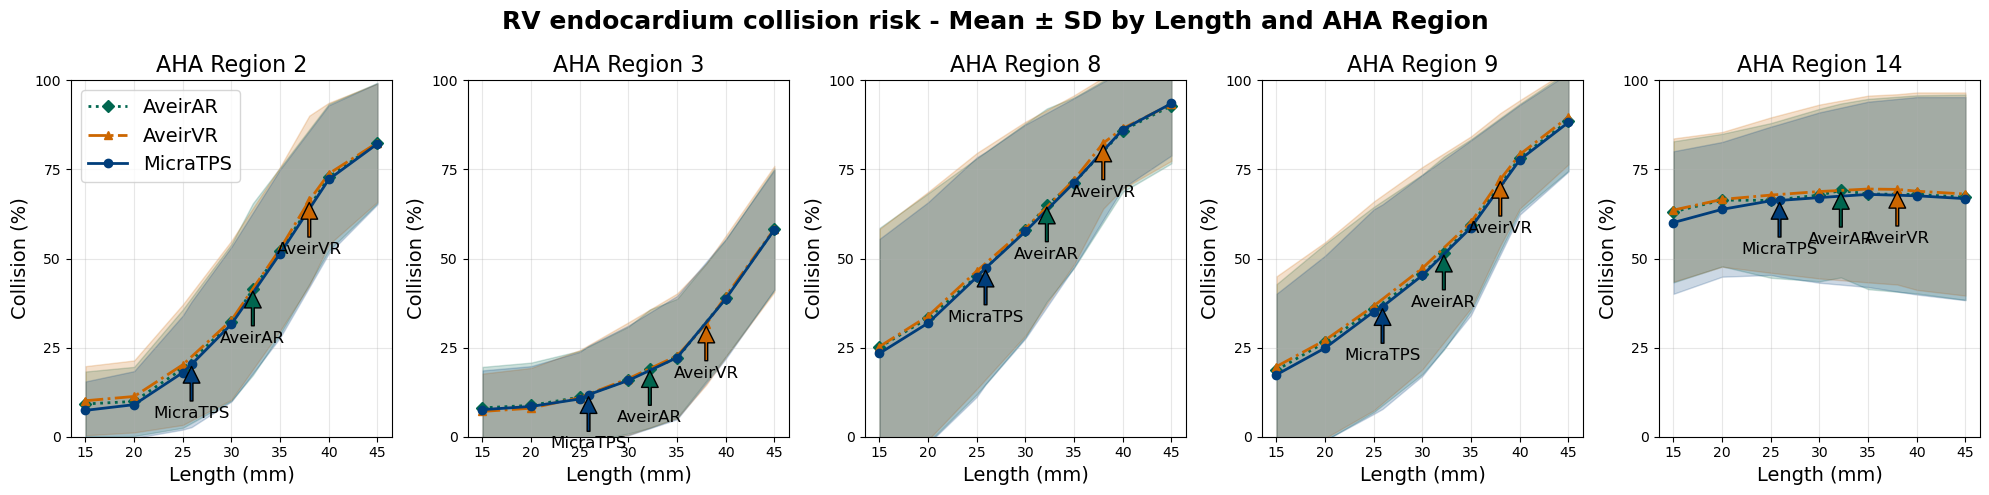

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_RV_Collision,18.9 ± 16.1,18.0 ± 17.5,49.7 ± 34.7,38.7 ± 30.4,69.2 ± 23.5,5.4 ± 8.0,23.4 ± 26.9,23.0 ± 22.8,33.0 ± 31.3
Micra_L15_RV_Collision,7.7 ± 8.4,12.1 ± 18.5,22.8 ± 32.7,16.4 ± 21.6,48.8 ± 20.1,2.0 ± 4.3,9.7 ± 19.3,5.0 ± 9.3,7.6 ± 15.8
Micra_L20_RV_Collision,9.7 ± 9.1,14.6 ± 20.0,34.7 ± 35.8,25.5 ± 26.2,62.6 ± 20.1,1.9 ± 4.2,13.1 ± 21.6,10.1 ± 13.9,18.8 ± 25.2
Micra_L25_RV_Collision,16.1 ± 13.5,18.8 ± 19.3,46.6 ± 35.1,36.8 ± 30.0,68.4 ± 22.4,4.8 ± 6.9,21.4 ± 26.3,21.1 ± 22.2,30.4 ± 30.7
Micra_L30_RV_Collision,34.0 ± 20.5,23.7 ± 18.4,61.1 ± 32.4,49.3 ± 29.9,72.6 ± 24.6,14.1 ± 12.7,35.9 ± 28.5,37.1 ± 25.4,47.1 ± 30.5
Micra_L35_RV_Collision,58.6 ± 20.8,30.8 ± 20.3,76.4 ± 22.5,64.5 ± 26.8,75.0 ± 25.2,29.4 ± 15.0,60.1 ± 22.0,56.4 ± 24.1,65.3 ± 27.4
Micra_L40_RV_Collision,78.9 ± 17.5,50.2 ± 16.4,88.8 ± 13.9,82.3 ± 15.2,76.2 ± 24.6,60.7 ± 15.5,82.5 ± 16.1,82.4 ± 14.0,86.0 ± 14.2
Micra_L45_RV_Collision,86.1 ± 15.2,66.6 ± 13.1,95.9 ± 8.5,92.3 ± 10.6,78.9 ± 22.6,86.0 ± 12.4,95.3 ± 8.4,96.5 ± 6.1,97.8 ± 4.6
AveirAR_L32.2_RV_Collision,43.6 ± 23.4,26.5 ± 19.1,69.6 ± 27.4,56.5 ± 29.0,73.0 ± 25.4,18.7 ± 15.7,46.7 ± 27.3,46.9 ± 26.0,57.0 ± 28.7
AveirAR_L15_RV_Collision,8.7 ± 8.6,13.9 ± 20.3,22.9 ± 32.0,16.3 ± 21.3,49.0 ± 19.6,2.1 ± 4.4,9.6 ± 18.3,5.1 ± 9.6,7.6 ± 15.8


Y OFFSET: -15
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/RV_Collision_by_AHA_region.png


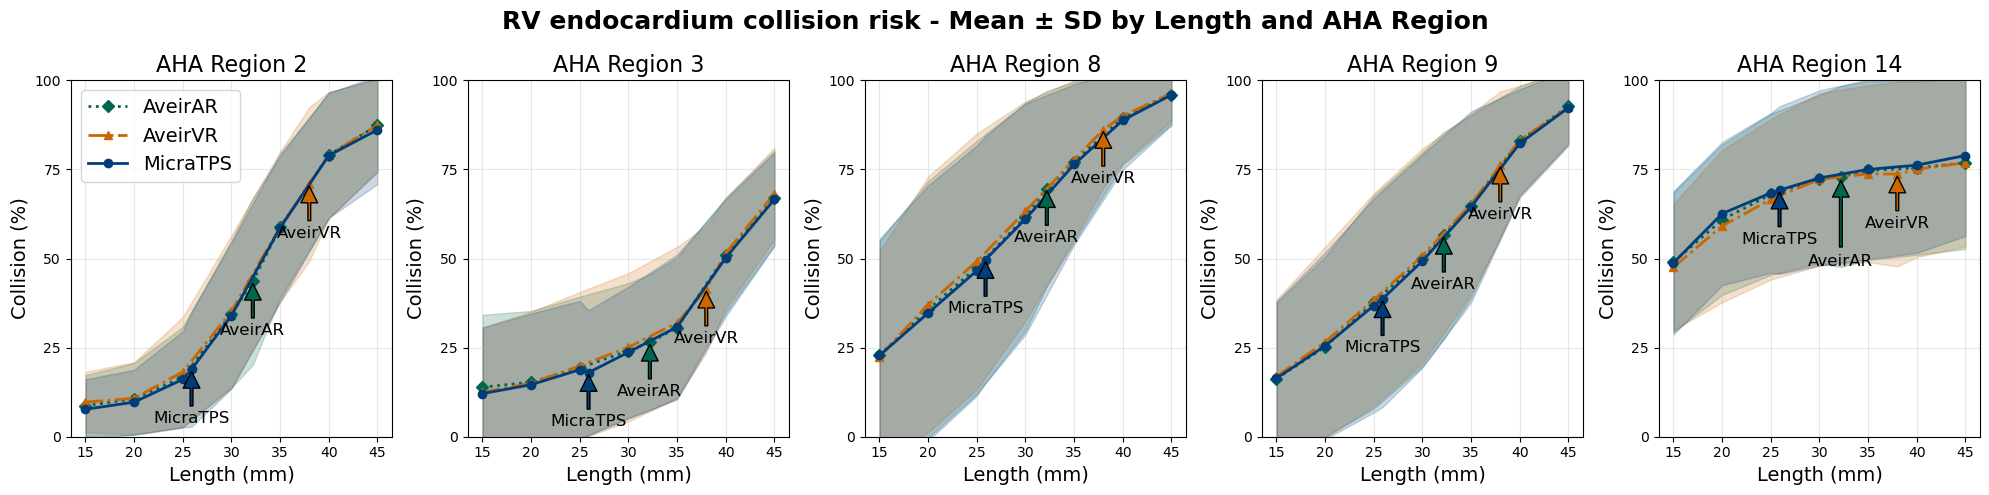

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_TV_Collision_Cone,7.8 ± 16.5,69.1 ± 30.1,0.1 ± 1.3,10.8 ± 16.7,0.0 ± 0.0,24.1 ± 26.0,0.9 ± 3.5,10.0 ± 13.4,3.7 ± 8.0
Micra_L15_TV_Collision_Cone,8.6 ± 17.5,69.0 ± 28.8,0.3 ± 2.0,11.3 ± 15.5,0.0 ± 0.0,26.3 ± 25.9,1.4 ± 4.6,11.1 ± 13.6,4.5 ± 8.9
Micra_L20_TV_Collision_Cone,8.3 ± 17.1,69.4 ± 29.9,0.2 ± 2.0,11.0 ± 16.0,0.0 ± 0.0,25.5 ± 26.1,1.2 ± 4.1,10.4 ± 12.8,4.6 ± 8.7
Micra_L25_TV_Collision_Cone,7.8 ± 16.5,69.3 ± 30.0,0.1 ± 1.3,10.9 ± 16.7,0.0 ± 0.0,24.4 ± 26.4,0.9 ± 3.5,10.2 ± 13.4,3.8 ± 8.0
Micra_L30_TV_Collision_Cone,7.7 ± 16.5,68.4 ± 30.4,0.1 ± 1.2,10.4 ± 16.2,0.0 ± 0.0,23.9 ± 25.9,0.8 ± 3.4,9.7 ± 13.0,3.5 ± 7.7
Micra_L35_TV_Collision_Cone,7.5 ± 16.3,67.7 ± 30.6,0.1 ± 0.8,9.8 ± 15.7,0.0 ± 0.0,22.8 ± 25.4,0.8 ± 3.2,9.0 ± 12.2,3.1 ± 7.2
Micra_L40_TV_Collision_Cone,7.2 ± 15.9,66.5 ± 30.6,0.0 ± 0.7,9.2 ± 15.0,0.0 ± 0.0,22.1 ± 25.2,0.7 ± 2.8,8.2 ± 11.4,3.0 ± 6.8
Micra_L45_TV_Collision_Cone,7.0 ± 15.6,65.9 ± 30.7,0.0 ± 0.7,8.6 ± 14.3,0.0 ± 0.0,21.3 ± 25.2,0.6 ± 2.6,7.5 ± 10.8,2.7 ± 6.3
AveirAR_L32.2_TV_Collision_Cone,7.7 ± 16.5,68.6 ± 30.4,0.1 ± 1.3,10.7 ± 16.6,0.0 ± 0.0,24.3 ± 26.2,0.9 ± 3.5,9.9 ± 13.4,3.7 ± 8.0
AveirAR_L15_TV_Collision_Cone,9.0 ± 17.9,70.4 ± 28.6,0.4 ± 2.3,12.3 ± 16.3,0.0 ± 0.0,27.5 ± 26.6,1.6 ± 4.9,12.4 ± 14.8,4.9 ± 9.7


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/TV_Collision_Cone_by_AHA_region.png


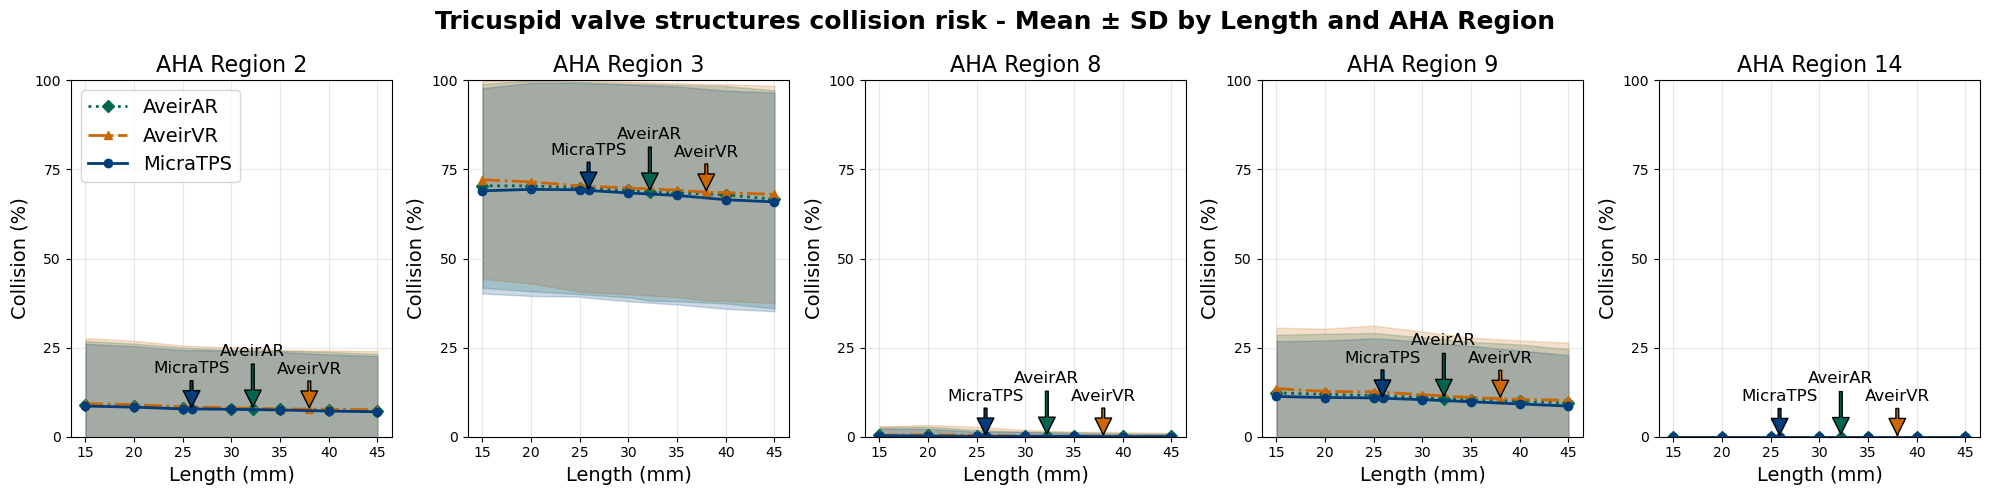

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_TV_Collision_Cone,9.0 ± 18.1,72.3 ± 28.3,0.4 ± 2.6,13.8 ± 19.7,0.0 ± 0.0,29.3 ± 27.9,1.6 ± 5.2,13.8 ± 16.8,5.8 ± 10.4
Micra_L15_TV_Collision_Cone,9.5 ± 18.5,72.2 ± 27.7,0.5 ± 2.7,13.1 ± 16.8,0.0 ± 0.0,30.1 ± 27.3,1.8 ± 5.6,13.7 ± 15.5,5.8 ± 11.1
Micra_L20_TV_Collision_Cone,9.1 ± 18.1,72.5 ± 28.4,0.6 ± 3.1,13.6 ± 19.2,0.0 ± 0.0,30.3 ± 27.1,2.0 ± 6.0,13.3 ± 15.9,6.7 ± 11.0
Micra_L25_TV_Collision_Cone,9.0 ± 18.1,72.2 ± 28.5,0.5 ± 2.7,14.0 ± 19.9,0.0 ± 0.0,29.5 ± 27.6,1.7 ± 5.3,14.0 ± 16.9,6.1 ± 10.4
Micra_L30_TV_Collision_Cone,8.5 ± 17.4,71.4 ± 29.8,0.4 ± 2.3,13.4 ± 19.3,0.0 ± 0.0,29.2 ± 29.0,1.4 ± 4.8,13.4 ± 16.1,5.8 ± 10.3
Micra_L35_TV_Collision_Cone,8.3 ± 17.2,70.7 ± 29.9,0.3 ± 1.8,12.6 ± 18.6,0.0 ± 0.0,27.9 ± 28.8,1.2 ± 4.3,12.4 ± 15.1,5.0 ± 9.3
Micra_L40_TV_Collision_Cone,8.3 ± 17.1,70.3 ± 30.0,0.3 ± 1.8,12.0 ± 18.1,0.0 ± 0.0,27.1 ± 28.5,1.2 ± 4.0,11.7 ± 14.7,4.7 ± 8.9
Micra_L45_TV_Collision_Cone,8.1 ± 16.9,69.9 ± 29.9,0.4 ± 2.1,11.4 ± 17.2,0.0 ± 0.0,26.7 ± 28.2,1.1 ± 3.8,11.1 ± 13.9,4.6 ± 8.7
AveirAR_L32.2_TV_Collision_Cone,8.9 ± 18.1,72.4 ± 28.6,0.4 ± 2.4,13.8 ± 19.7,0.0 ± 0.0,29.7 ± 28.9,1.5 ± 5.0,13.9 ± 16.7,5.8 ± 10.4
AveirAR_L15_TV_Collision_Cone,10.0 ± 19.1,73.0 ± 27.1,0.6 ± 3.0,14.1 ± 17.4,0.0 ± 0.0,31.2 ± 27.5,2.1 ± 6.0,14.9 ± 16.1,6.4 ± 11.3


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/TV_Collision_Cone_by_AHA_region.png


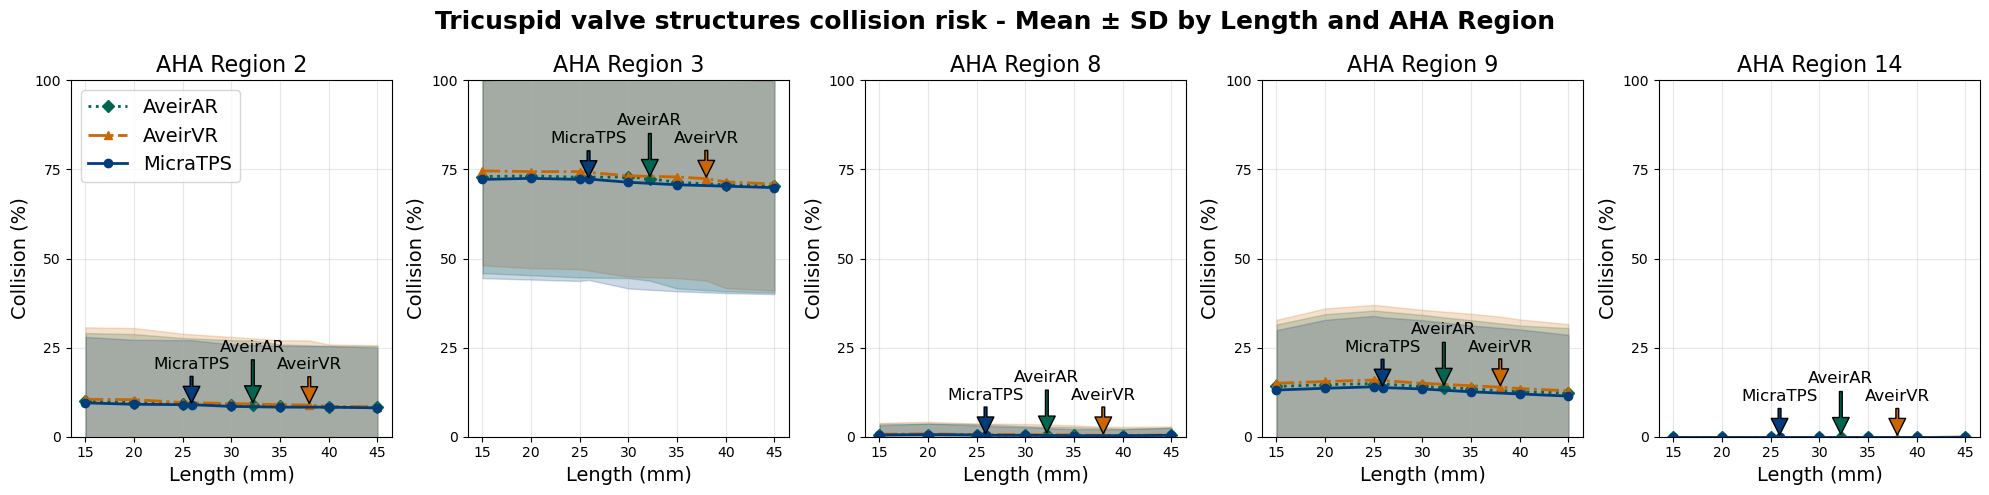

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_TV_Collision,10.1 ± 19.8,74.3 ± 28.8,0.9 ± 3.4,17.6 ± 22.3,0.0 ± 0.0,35.8 ± 29.1,2.6 ± 7.3,18.8 ± 19.4,8.9 ± 14.6
Micra_L15_TV_Collision,10.9 ± 21.0,73.0 ± 29.2,0.7 ± 3.5,15.4 ± 19.0,0.0 ± 0.0,34.5 ± 28.7,2.6 ± 7.6,15.8 ± 16.9,7.3 ± 12.6
Micra_L20_TV_Collision,10.3 ± 19.9,74.0 ± 29.2,1.0 ± 3.5,16.5 ± 21.8,0.0 ± 0.0,35.5 ± 28.8,2.6 ± 7.3,16.7 ± 19.1,7.7 ± 12.6
Micra_L25_TV_Collision,10.1 ± 19.8,74.3 ± 28.8,0.9 ± 3.4,17.6 ± 22.3,0.0 ± 0.0,35.8 ± 29.1,2.6 ± 7.3,18.8 ± 19.4,8.9 ± 14.6
Micra_L30_TV_Collision,9.5 ± 18.3,73.0 ± 28.6,0.9 ± 3.4,17.6 ± 22.0,0.0 ± 0.0,34.3 ± 27.6,2.5 ± 6.8,19.3 ± 18.9,9.9 ± 14.4
Micra_L35_TV_Collision,9.3 ± 18.2,72.6 ± 28.5,0.9 ± 3.4,17.0 ± 21.2,0.0 ± 0.0,34.0 ± 27.3,2.5 ± 6.8,18.5 ± 18.1,9.2 ± 13.3
Micra_L40_TV_Collision,9.3 ± 18.1,72.0 ± 28.7,1.5 ± 3.8,16.0 ± 21.0,0.0 ± 0.0,33.1 ± 27.7,2.7 ± 6.5,16.8 ± 18.1,8.2 ± 13.3
Micra_L45_TV_Collision,9.2 ± 17.9,72.1 ± 28.8,1.6 ± 3.9,15.7 ± 21.2,0.4 ± 2.0,32.3 ± 28.2,2.7 ± 6.5,16.3 ± 18.3,7.4 ± 13.3
AveirAR_L32.2_TV_Collision,10.0 ± 19.3,74.1 ± 28.8,0.9 ± 3.4,18.1 ± 22.6,0.0 ± 0.0,35.5 ± 27.7,2.7 ± 7.3,19.6 ± 19.3,10.0 ± 14.5
AveirAR_L15_TV_Collision,11.1 ± 21.2,73.2 ± 29.2,1.1 ± 4.7,15.6 ± 19.0,0.0 ± 0.0,35.8 ± 28.3,3.2 ± 9.3,16.3 ± 17.0,8.4 ± 13.2


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/TV_Collision_by_AHA_region.png


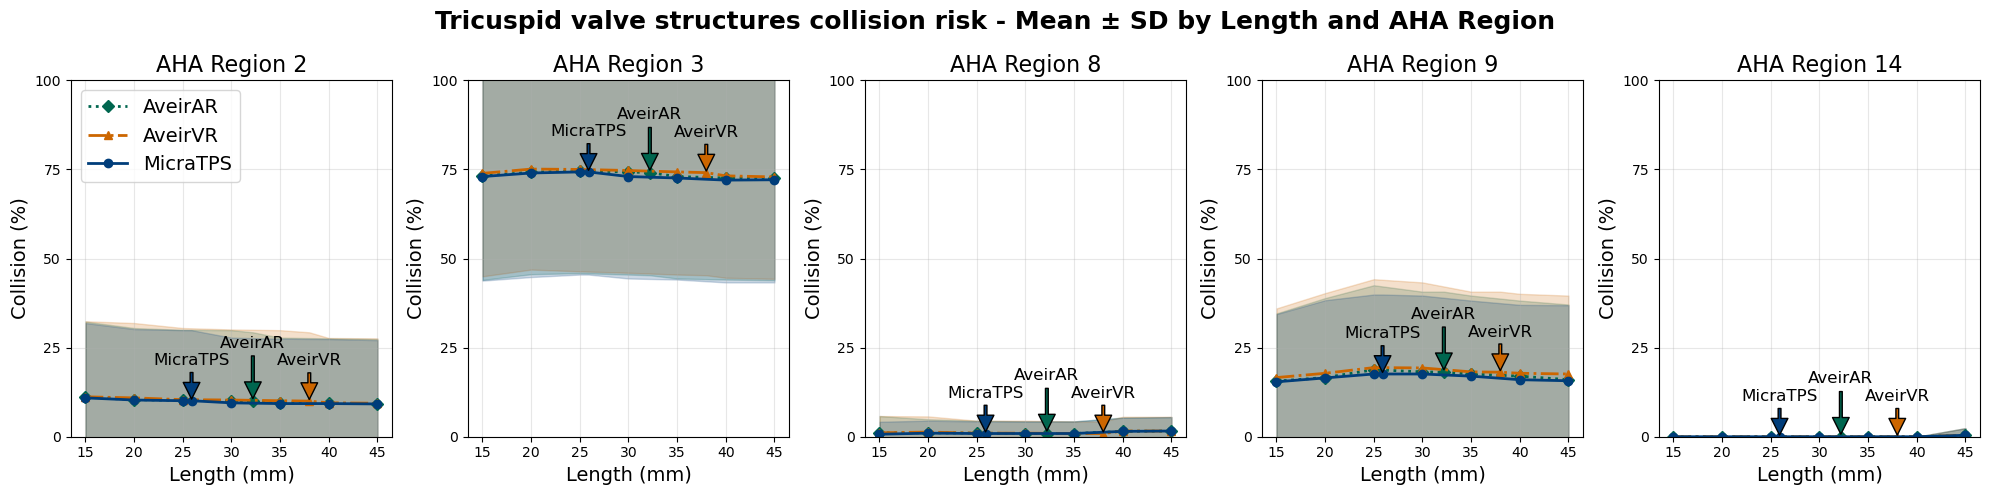

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_PM_Collision_Cone,1.6 ± 5.0,14.8 ± 12.0,21.8 ± 21.0,31.1 ± 17.6,9.5 ± 12.5,25.9 ± 17.0,11.9 ± 15.5,39.5 ± 14.8,44.0 ± 11.2
Micra_L15_PM_Collision_Cone,1.7 ± 4.3,15.8 ± 12.0,23.9 ± 22.2,29.4 ± 14.6,9.7 ± 11.1,27.2 ± 17.8,14.1 ± 17.3,37.0 ± 12.3,42.1 ± 10.5
Micra_L20_PM_Collision_Cone,1.6 ± 4.2,15.3 ± 12.0,22.3 ± 21.0,30.9 ± 17.2,10.1 ± 12.8,26.3 ± 17.7,12.3 ± 15.8,39.2 ± 14.6,46.8 ± 11.4
Micra_L25_PM_Collision_Cone,1.4 ± 4.8,14.9 ± 11.9,22.0 ± 21.1,31.3 ± 17.8,9.5 ± 12.5,26.0 ± 17.3,11.9 ± 15.6,40.1 ± 14.9,44.4 ± 11.3
Micra_L30_PM_Collision_Cone,1.6 ± 5.1,15.0 ± 11.8,21.7 ± 21.2,30.0 ± 17.3,9.1 ± 12.1,26.5 ± 17.4,11.8 ± 15.5,38.4 ± 14.8,43.0 ± 11.7
Micra_L35_PM_Collision_Cone,1.9 ± 5.3,15.3 ± 12.5,21.2 ± 21.0,28.8 ± 17.0,8.8 ± 11.5,26.3 ± 17.8,11.4 ± 15.0,37.1 ± 14.7,41.0 ± 11.9
Micra_L40_PM_Collision_Cone,2.0 ± 5.3,14.6 ± 12.1,19.9 ± 20.1,27.8 ± 16.5,8.5 ± 11.1,25.4 ± 17.4,10.7 ± 14.5,35.8 ± 14.6,39.5 ± 11.9
Micra_L45_PM_Collision_Cone,2.0 ± 5.3,14.6 ± 11.6,19.3 ± 19.7,26.6 ± 16.3,8.1 ± 10.8,24.5 ± 16.9,10.3 ± 14.2,34.4 ± 14.4,38.2 ± 11.8
AveirAR_L32.2_PM_Collision_Cone,2.1 ± 5.7,15.4 ± 12.5,22.6 ± 21.7,31.3 ± 17.9,9.6 ± 12.5,27.9 ± 17.8,12.5 ± 15.7,39.9 ± 15.1,44.5 ± 11.8
AveirAR_L15_PM_Collision_Cone,1.9 ± 4.9,17.5 ± 11.9,25.4 ± 23.0,31.7 ± 15.4,11.0 ± 12.2,29.6 ± 18.7,15.5 ± 18.1,39.8 ± 12.7,45.4 ± 11.0


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/PM_Collision_Cone_by_AHA_region.png


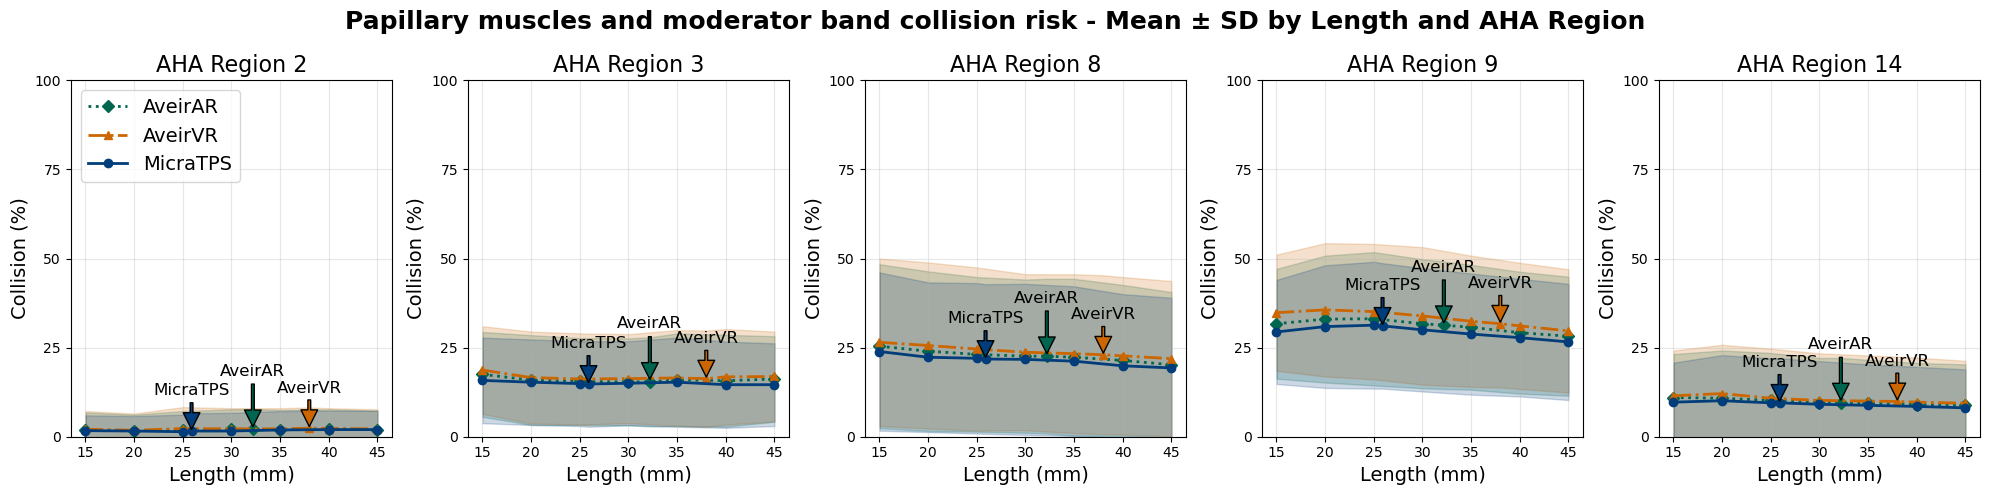

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_PM_Collision_Cone,2.9 ± 6.4,16.1 ± 13.2,24.3 ± 22.7,37.6 ± 20.5,12.4 ± 14.6,30.6 ± 19.0,13.5 ± 16.7,49.3 ± 14.6,53.6 ± 12.0
Micra_L15_PM_Collision_Cone,1.9 ± 4.7,16.8 ± 12.0,25.7 ± 23.2,32.2 ± 15.9,11.9 ± 12.7,30.2 ± 19.0,15.5 ± 18.2,40.4 ± 13.2,47.6 ± 10.7
Micra_L20_PM_Collision_Cone,2.2 ± 5.3,16.5 ± 13.0,24.7 ± 23.1,35.7 ± 19.3,13.0 ± 14.9,31.3 ± 19.6,13.9 ± 17.3,46.1 ± 15.2,55.4 ± 11.7
Micra_L25_PM_Collision_Cone,2.2 ± 5.9,16.4 ± 13.3,24.5 ± 22.9,37.7 ± 20.5,12.5 ± 14.7,30.7 ± 19.2,13.5 ± 16.9,49.4 ± 14.6,53.8 ± 11.9
Micra_L30_PM_Collision_Cone,3.2 ± 6.9,17.0 ± 13.1,24.3 ± 22.8,36.9 ± 20.3,12.3 ± 14.3,32.7 ± 19.7,13.7 ± 16.8,48.3 ± 14.9,52.9 ± 11.8
Micra_L35_PM_Collision_Cone,3.7 ± 7.5,17.8 ± 14.3,24.5 ± 23.2,36.1 ± 19.9,12.1 ± 14.0,33.2 ± 19.7,13.9 ± 17.3,46.5 ± 15.3,51.5 ± 11.7
Micra_L40_PM_Collision_Cone,3.8 ± 7.6,19.6 ± 14.0,23.9 ± 23.0,35.3 ± 19.4,11.7 ± 13.8,32.7 ± 19.5,13.3 ± 17.0,45.5 ± 15.1,50.0 ± 12.1
Micra_L45_PM_Collision_Cone,4.3 ± 8.1,19.9 ± 14.4,23.3 ± 22.6,34.3 ± 19.2,11.6 ± 13.5,31.9 ± 18.9,12.8 ± 16.3,44.3 ± 14.9,48.9 ± 11.7
AveirAR_L32.2_PM_Collision_Cone,3.8 ± 7.6,18.4 ± 14.6,25.7 ± 23.9,38.2 ± 20.6,13.1 ± 14.7,34.4 ± 20.4,14.6 ± 17.6,49.8 ± 14.9,55.0 ± 12.0
AveirAR_L15_PM_Collision_Cone,2.4 ± 5.7,18.9 ± 11.9,26.8 ± 23.7,34.7 ± 16.7,12.6 ± 13.5,32.8 ± 20.3,16.7 ± 19.0,43.3 ± 13.7,51.0 ± 11.3


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/PM_Collision_Cone_by_AHA_region.png


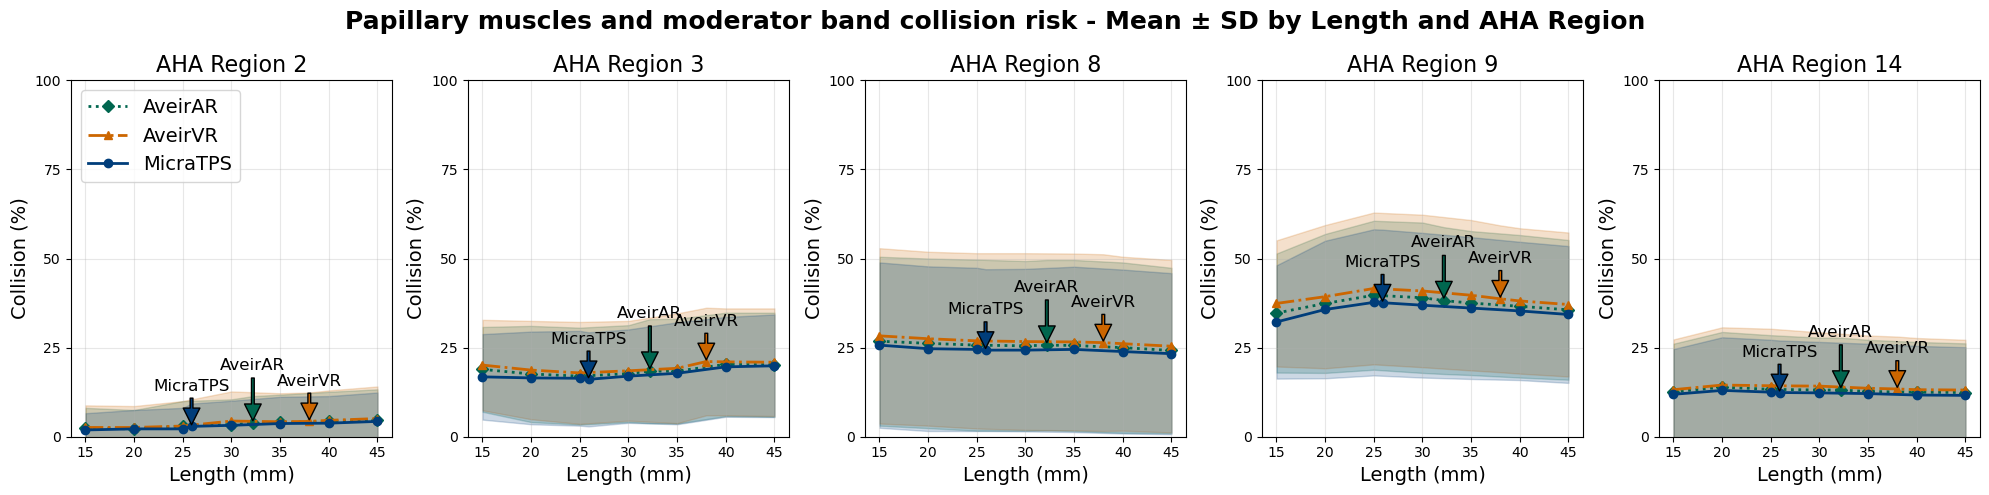

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_PM_Collision,4.2 ± 7.3,18.1 ± 14.2,27.1 ± 25.0,42.9 ± 22.3,15.5 ± 16.5,37.2 ± 20.5,15.7 ± 18.4,56.4 ± 14.6,61.8 ± 11.5
Micra_L15_PM_Collision,3.0 ± 6.3,18.3 ± 12.4,28.0 ± 25.2,35.8 ± 17.7,14.2 ± 14.1,35.8 ± 19.4,17.2 ± 19.1,44.3 ± 14.8,54.1 ± 11.5
Micra_L20_PM_Collision,3.0 ± 5.6,17.2 ± 13.6,27.5 ± 24.2,40.2 ± 22.1,15.0 ± 16.5,36.7 ± 22.3,15.4 ± 18.1,52.0 ± 17.3,63.3 ± 11.7
Micra_L25_PM_Collision,3.7 ± 6.4,17.9 ± 14.0,27.0 ± 25.1,42.9 ± 22.3,15.5 ± 16.5,35.9 ± 21.4,15.4 ± 18.3,56.4 ± 14.6,61.8 ± 11.5
Micra_L30_PM_Collision,4.4 ± 7.4,18.9 ± 14.9,26.3 ± 25.0,41.8 ± 21.8,15.5 ± 15.8,36.4 ± 19.2,14.8 ± 18.0,54.2 ± 15.0,59.6 ± 12.6
Micra_L35_PM_Collision,6.0 ± 9.5,20.0 ± 15.6,26.6 ± 25.1,42.4 ± 22.1,17.6 ± 15.7,37.0 ± 18.8,14.8 ± 17.4,54.3 ± 15.5,59.6 ± 12.6
Micra_L40_PM_Collision,6.6 ± 10.3,20.1 ± 15.4,26.9 ± 25.6,41.7 ± 22.5,17.1 ± 15.4,36.2 ± 18.6,14.6 ± 18.0,53.9 ± 16.5,59.0 ± 12.7
Micra_L45_PM_Collision,6.8 ± 10.5,20.6 ± 14.8,26.8 ± 24.8,40.1 ± 22.1,17.2 ± 15.5,35.6 ± 17.8,14.7 ± 17.9,52.1 ± 16.1,57.3 ± 11.8
AveirAR_L32.2_PM_Collision,5.2 ± 8.2,20.6 ± 15.5,27.6 ± 26.0,43.8 ± 22.3,17.4 ± 16.0,38.9 ± 20.9,15.6 ± 18.7,56.9 ± 14.2,62.2 ± 12.1
AveirAR_L15_PM_Collision,3.1 ± 6.7,19.2 ± 13.1,28.8 ± 25.6,38.1 ± 17.9,15.1 ± 15.0,38.3 ± 20.3,18.0 ± 19.6,46.9 ± 14.2,57.0 ± 11.6


Y OFFSET: 10
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/PM_Collision_by_AHA_region.png


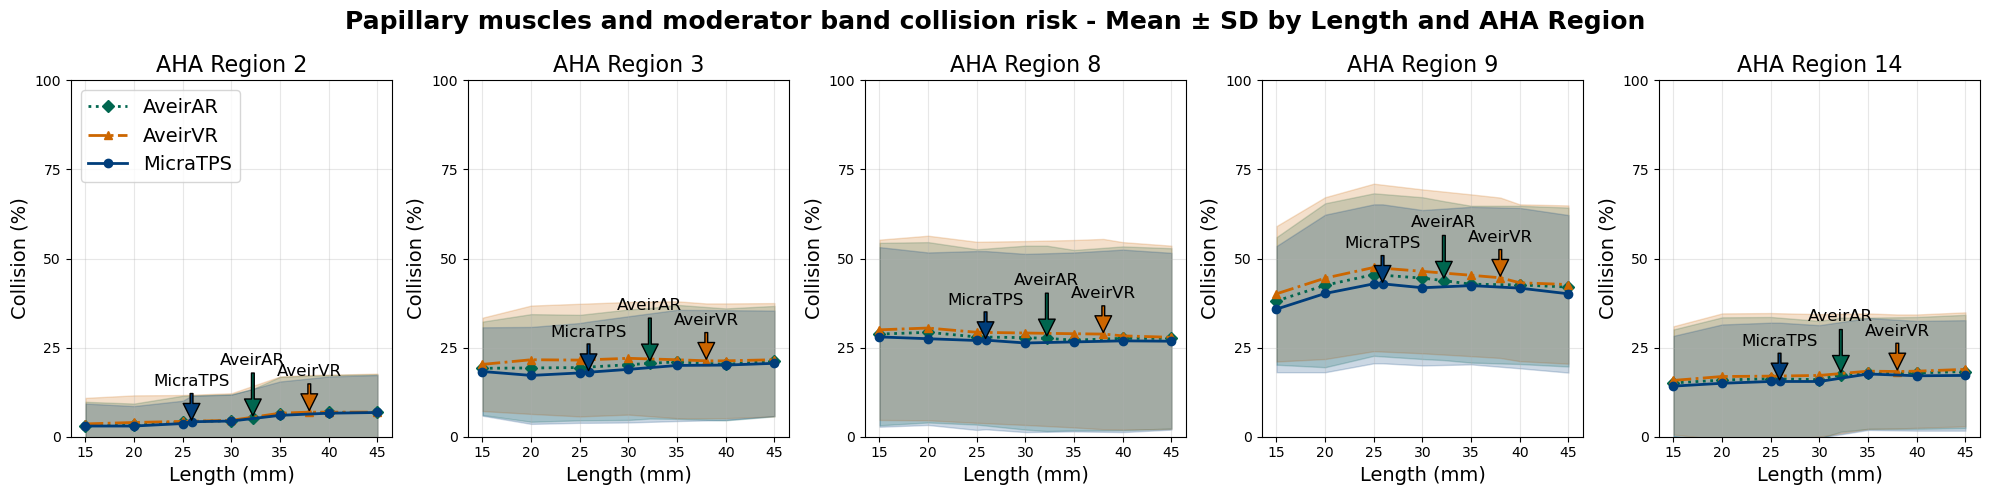

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_Combined_Collision_Cone,21.8 ± 20.8,81.5 ± 21.1,53.3 ± 26.6,63.5 ± 16.7,58.4 ± 30.7,46.7 ± 22.4,28.8 ± 24.7,59.1 ± 17.5,63.1 ± 18.0
Micra_L15_Combined_Collision_Cone,12.2 ± 20.1,80.2 ± 20.3,41.1 ± 23.0,48.8 ± 14.6,52.6 ± 22.5,49.1 ± 21.8,21.0 ± 18.4,46.2 ± 14.1,47.5 ± 10.5
Micra_L20_Combined_Collision_Cone,13.5 ± 19.3,80.9 ± 21.7,45.5 ± 25.8,55.5 ± 14.2,56.7 ± 27.0,47.7 ± 22.5,21.8 ± 19.7,50.9 ± 12.8,58.8 ± 14.8
Micra_L25_Combined_Collision_Cone,19.2 ± 19.4,81.0 ± 22.1,51.8 ± 26.7,62.9 ± 16.4,58.3 ± 30.3,46.2 ± 22.3,27.2 ± 23.9,58.9 ± 17.0,62.7 ± 17.8
Micra_L30_Combined_Collision_Cone,32.1 ± 22.3,82.3 ± 20.1,60.3 ± 25.3,67.3 ± 16.9,58.5 ± 32.4,49.9 ± 22.5,37.1 ± 25.6,63.6 ± 18.3,67.7 ± 18.1
Micra_L35_Combined_Collision_Cone,49.2 ± 20.3,83.6 ± 17.9,70.4 ± 22.0,72.1 ± 15.9,59.2 ± 33.9,54.9 ± 20.8,54.4 ± 20.8,69.7 ± 16.5,75.0 ± 17.3
Micra_L40_Combined_Collision_Cone,68.5 ± 20.2,85.2 ± 17.9,80.4 ± 21.7,81.6 ± 13.2,58.9 ± 34.3,68.8 ± 17.7,73.0 ± 19.1,82.9 ± 10.6,87.7 ± 12.5
Micra_L45_Combined_Collision_Cone,79.4 ± 17.4,87.9 ± 17.0,90.0 ± 19.9,86.7 ± 13.6,58.4 ± 34.5,88.2 ± 9.9,91.8 ± 13.1,90.7 ± 9.4,94.6 ± 8.3
AveirAR_L32.2_Combined_Collision_Cone,39.6 ± 21.9,83.5 ± 19.1,65.6 ± 24.5,70.8 ± 16.2,60.5 ± 32.6,52.9 ± 22.4,44.7 ± 24.9,68.2 ± 17.2,72.4 ± 17.4
AveirAR_L15_Combined_Collision_Cone,13.2 ± 20.5,82.1 ± 18.7,43.6 ± 23.4,52.3 ± 14.8,55.4 ± 22.8,51.6 ± 21.2,22.9 ± 19.3,49.7 ± 14.5,50.7 ± 11.0


Y OFFSET: -20
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/Combined_Collision_Cone_by_AHA_region.png


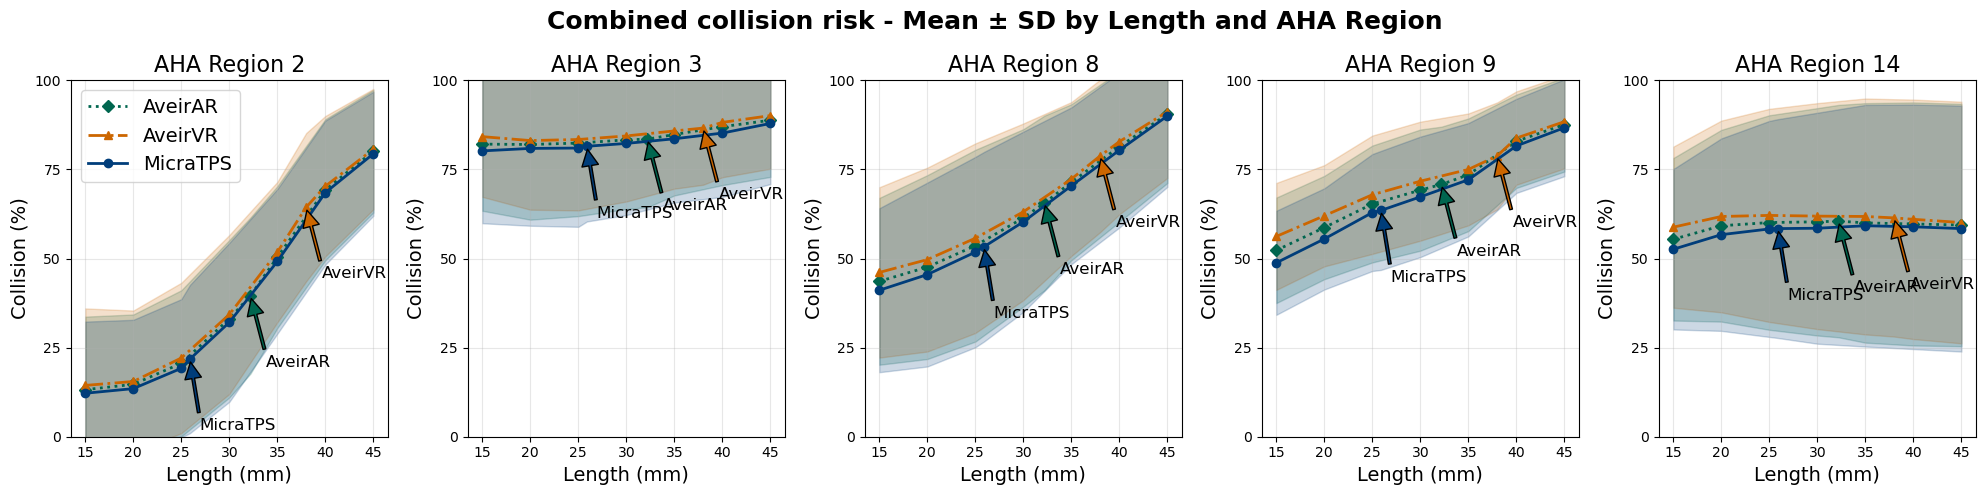

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_Combined_Collision_Cone,30.5 ± 22.3,86.7 ± 16.9,61.6 ± 25.8,74.9 ± 15.9,70.7 ± 23.6,54.0 ± 22.6,36.0 ± 26.8,72.2 ± 17.8,73.5 ± 16.9
Micra_L15_Combined_Collision_Cone,18.1 ± 22.5,85.4 ± 15.9,48.2 ± 24.7,55.3 ± 15.1,66.9 ± 16.5,54.6 ± 21.0,25.5 ± 20.6,51.6 ± 14.5,54.3 ± 11.5
Micra_L20_Combined_Collision_Cone,19.6 ± 21.5,85.5 ± 17.9,52.7 ± 26.6,64.7 ± 14.3,70.3 ± 20.5,54.4 ± 21.9,27.3 ± 22.9,59.7 ± 13.4,68.7 ± 14.9
Micra_L25_Combined_Collision_Cone,27.8 ± 21.5,86.6 ± 17.0,60.2 ± 26.5,74.2 ± 15.5,70.9 ± 23.2,53.5 ± 22.6,34.0 ± 26.4,71.2 ± 17.2,73.0 ± 16.9
Micra_L30_Combined_Collision_Cone,41.0 ± 22.1,87.4 ± 15.8,68.5 ± 23.6,78.1 ± 15.6,70.0 ± 25.8,58.3 ± 22.1,45.4 ± 26.5,76.2 ± 17.2,78.0 ± 15.0
Micra_L35_Combined_Collision_Cone,60.3 ± 18.4,89.3 ± 13.2,77.8 ± 20.0,82.5 ± 14.3,69.6 ± 27.0,64.6 ± 18.2,62.9 ± 19.6,81.4 ± 14.4,84.3 ± 13.4
Micra_L40_Combined_Collision_Cone,79.2 ± 15.6,91.9 ± 11.1,88.3 ± 15.9,88.6 ± 12.3,68.6 ± 27.5,80.1 ± 14.6,83.1 ± 14.8,91.1 ± 9.6,93.6 ± 9.1
Micra_L45_Combined_Collision_Cone,87.0 ± 13.0,94.0 ± 9.6,93.8 ± 13.8,92.2 ± 12.0,67.8 ± 27.9,93.6 ± 7.2,95.1 ± 9.1,97.5 ± 5.6,98.3 ± 4.6
AveirAR_L32.2_Combined_Collision_Cone,51.3 ± 21.2,89.9 ± 12.5,74.1 ± 21.7,81.4 ± 14.5,71.3 ± 25.4,62.2 ± 20.9,53.6 ± 24.1,80.6 ± 15.2,83.0 ± 12.7
AveirAR_L15_Combined_Collision_Cone,20.7 ± 23.2,87.1 ± 14.6,50.7 ± 25.0,58.5 ± 14.8,70.2 ± 15.7,56.9 ± 20.6,27.7 ± 21.2,54.9 ± 14.2,57.8 ± 12.1


Y OFFSET: -20
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/Combined_Collision_Cone_by_AHA_region.png


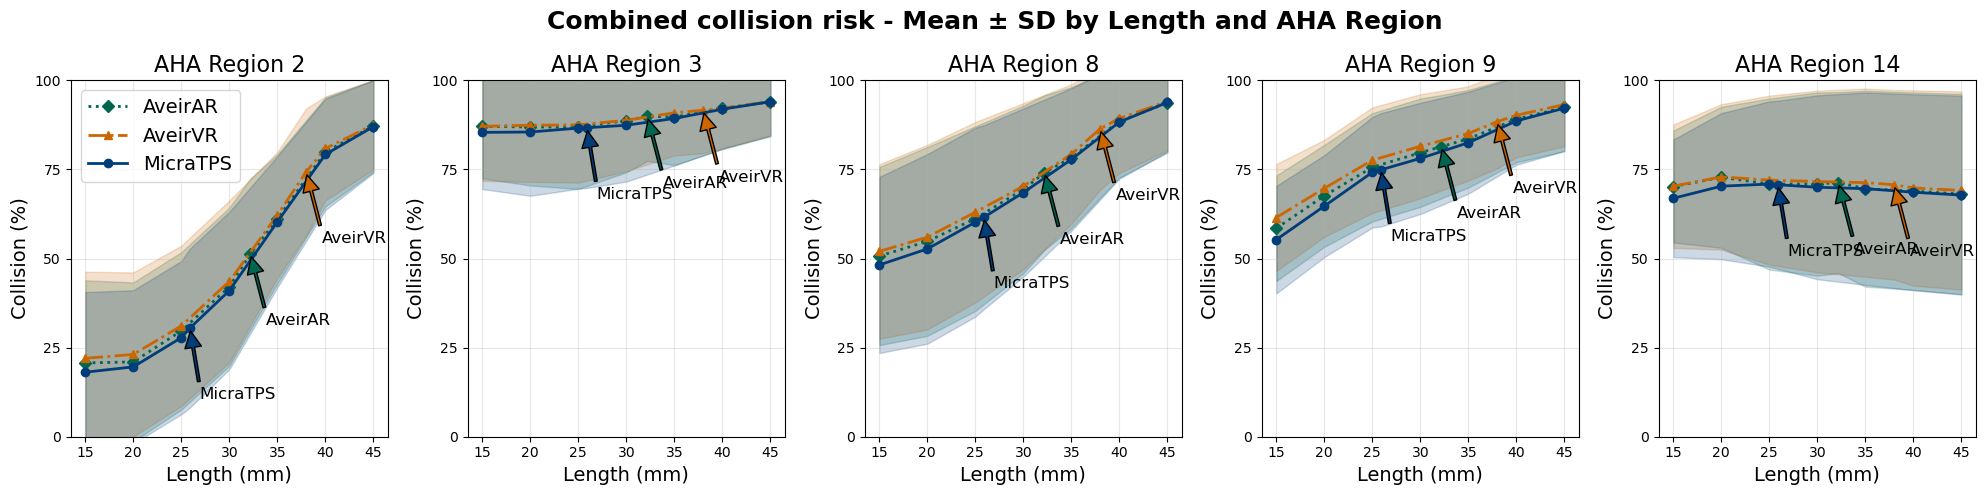

AHA region,2,3,8,9,14,20,21,22,23
Micra_L25.9_Combined_Collision,30.8 ± 21.2,91.1 ± 11.9,65.3 ± 26.4,81.3 ± 13.4,73.6 ± 23.9,62.0 ± 20.2,38.8 ± 25.4,80.4 ± 15.3,80.8 ± 13.1
Micra_L15_Combined_Collision,19.9 ± 22.7,88.1 ± 13.1,49.8 ± 26.0,57.4 ± 15.1,57.4 ± 20.2,61.0 ± 19.2,27.9 ± 21.4,55.1 ± 15.0,61.2 ± 12.1
Micra_L20_Combined_Collision,21.4 ± 20.7,90.5 ± 11.7,55.7 ± 27.2,69.0 ± 13.5,69.3 ± 21.5,61.6 ± 21.3,29.4 ± 21.6,65.9 ± 13.9,76.1 ± 12.6
Micra_L25_Combined_Collision,27.7 ± 20.4,92.0 ± 10.8,63.8 ± 26.6,80.5 ± 13.6,73.2 ± 22.9,61.3 ± 20.9,37.3 ± 24.5,79.9 ± 15.5,80.2 ± 13.2
Micra_L30_Combined_Collision,43.5 ± 19.5,91.8 ± 10.5,71.9 ± 24.5,83.7 ± 13.9,75.7 ± 23.7,61.9 ± 19.8,47.9 ± 25.2,83.3 ± 15.1,83.0 ± 15.1
Micra_L35_Combined_Collision,68.1 ± 15.6,94.0 ± 9.0,81.4 ± 18.2,88.7 ± 12.3,76.5 ± 23.8,70.3 ± 15.1,66.6 ± 17.6,88.2 ± 12.4,89.2 ± 11.9
Micra_L40_Combined_Collision,85.1 ± 14.3,95.2 ± 7.1,90.4 ± 13.3,92.2 ± 9.4,77.2 ± 23.7,82.5 ± 13.0,85.0 ± 14.3,94.0 ± 7.1,94.3 ± 8.4
Micra_L45_Combined_Collision,89.7 ± 13.9,96.0 ± 6.6,96.2 ± 8.1,95.6 ± 9.1,79.4 ± 22.1,94.8 ± 5.8,95.9 ± 7.3,99.3 ± 2.5,98.8 ± 3.3
AveirAR_L32.2_Combined_Collision,54.6 ± 19.5,93.6 ± 9.3,78.3 ± 21.1,86.4 ± 12.0,74.9 ± 24.2,68.0 ± 18.9,56.8 ± 23.3,86.8 ± 11.9,88.1 ± 11.0
AveirAR_L15_Combined_Collision,21.0 ± 22.6,89.6 ± 11.6,50.3 ± 25.2,59.1 ± 13.7,57.6 ± 19.9,63.0 ± 18.6,28.9 ± 21.1,57.7 ± 13.9,63.9 ± 11.5


Y OFFSET: -20
Axes(0.125,0.11;0.133621x0.77)
/data_fast/Work/MS_HF_cohort/images_cone10/plots/Combined_Collision_by_AHA_region.png


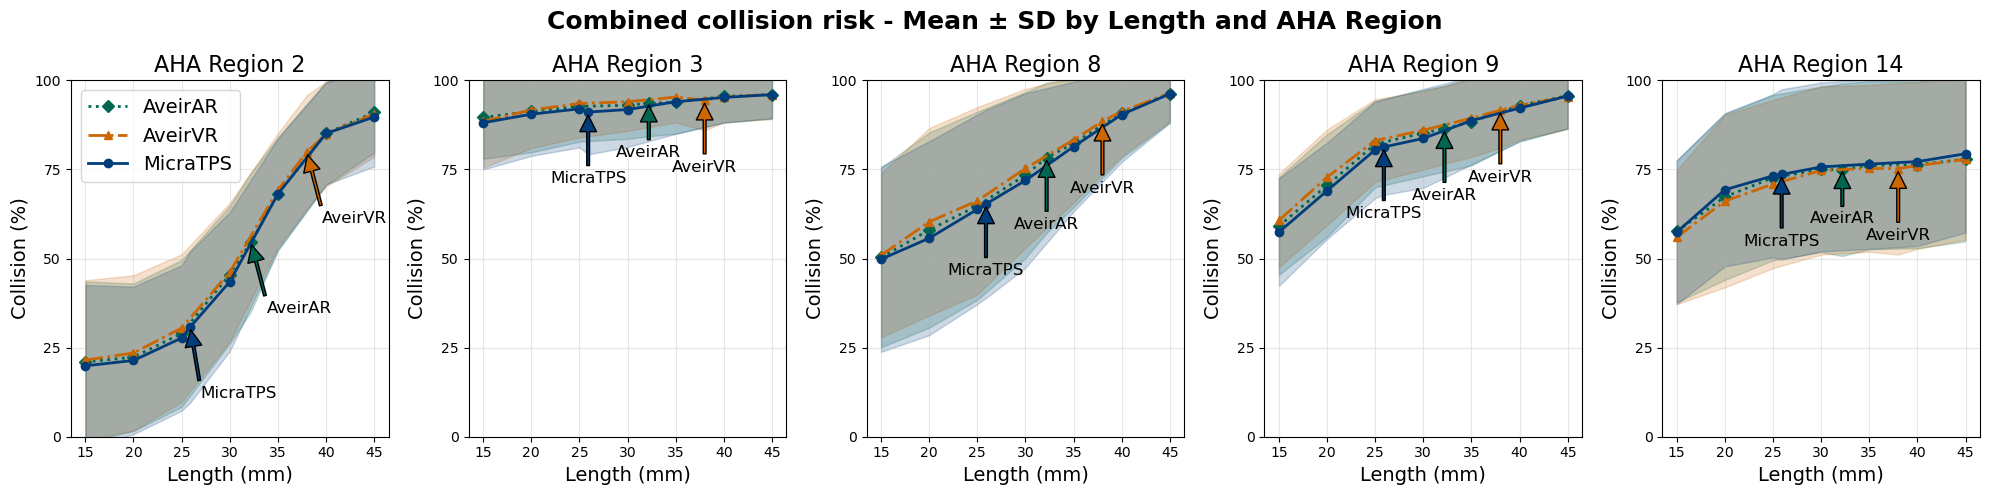

In [ ]:

def get_merged_df(collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision'], conestr=''): 
# Initialize empty merged DataFrame
    merged_df = None
    devices={
        "Micra": {"D": 6.7, "L": 25.9}, # AV/AV2
        "AveirAR": {"D": 6.5, "L": 32.2}, # atrial Aveir DR device 
        "AveirVR": {"D": 6.5, "L": 38} # Atrial Aveir DR device + 10mm
    }

    for device in ["Micra", "AveirAR" ,"AveirVR"]:
        D = devices[device]["D"]
        init_len = devices[device]["L"]
        
        # Calculate original volume
        vol = np.pi * ((D / 2) ** 2) * init_len

        lengths=[init_len, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
        diameters=[]
        # If we want to keep the same volume, calculate new diameter for each new length
        for length in lengths:
            new_D = np.sqrt(vol / (np.pi * length)) * 2
            diameters.append(new_D)
            #print(f"{length:8.0f}    | {new_D:8.3f}")        
        #coll_fields=['Combined_Collision']
        merged_df=read_AHA_csv(merged_df, device, lengths, collision_fields=collision_fields, conestr=conestr) #, diameters=diameters)

    ###################################################################################
    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)
    
    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    
    pivot_df = merged_df.set_index("AHA region").T
    pd.set_option('display.max_rows', None) # Show all rows in DataFrame display
    #display(pivot_df)
    pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary{conestr}.csv', index=True)
    return merged_df
def fig3_plots(merged_df): 
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    plot_collision_data_by_aha(merged_df, output_path=output_plot_path, plot_CS=False)
def fig5_plots(merged_df): #CSP per device plots
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    #plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    
    plot_collision_data_regions_as_lines(merged_df, output_path=output_plot_path, plot_CS=True)

    # NEW: Create summary statistics
    #summary_stats = create_summary_table(merged_df, output_path=output_plot_path)
    #print("\nSummary Statistics:")
    #display(summary_stats)

    
def fig3_plots_with_cone(merged_df, collision_fields): 
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images_cone10/plots'
    plot_collision_data_by_aha(merged_df, output_path=output_plot_path, plot_CS=False, collision_fields=collision_fields)

def fig5_plots_with_cone(merged_df, collision_fields): #CSP per device plots
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images_cone10/plots'
    #plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    
    plot_collision_data_regions_as_lines(merged_df, output_path=output_plot_path, plot_CS=True, collision_fields=collision_fields)

if __name__ == "__main__":
    #merged_df=get_merged_df()
    #fig3_plots(merged_df)
    #fig5_plots(merged_df)
    
    #collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
    ################
    # With cone
    ################
    
    collision_fields=['RV_Collision_Cone','TV_Collision_Cone', 'PM_Collision_Cone','Combined_Collision_Cone']
    
    conestr='_cone10_10'    
    merged_df=get_merged_df(collision_fields, conestr=conestr)
    fig3_plots_with_cone(merged_df, collision_fields)

    # collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
    # collision_fields=[ 'Combined_Collision'] #
    # conestr=''
    # merged_df=get_merged_df(collision_fields, conestr=conestr)
    # fig3_plots_with_cone(merged_df, collision_fields)

    for collision_field in [ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']: 
        conestr='_cone10_10'    
        merged_df=get_merged_df([collision_field+'_Cone'], conestr=conestr)
        fig3_plots_with_cone(merged_df, [collision_field+'_Cone'])
        conestr='_cone5_10'    
        merged_df=get_merged_df([collision_field+'_Cone'], conestr=conestr)
        fig3_plots_with_cone(merged_df, [collision_field+'_Cone'])
        conestr=''
        merged_df=get_merged_df([collision_field], conestr=conestr)
        fig3_plots_with_cone(merged_df, [collision_field])
        

In [ ]:
import pandas as pd
import numpy as np

mainpath='/data_fast/Work/MS_HF_cohort/images/'

for device in ['AveirVR', 'AveirAR', 'Micra']: # #
    if device == 'AveirVR':
        init_len= 38
    elif device == 'AveirAR': 
        init_len= 32.2
    elif device == 'Micra': 
        init_len = 25.9
    else: 
        print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')

    lengths=[init_len] #, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
    for length in lengths:
        all_collision_values = []
        for AHA_region in [2,3,8,9,14]: 
            csv_file=f'{mainpath}/{device}/csv/{AHA_region}_L{length}.csv'
            print(f'CSV file: {csv_file}')  
            df = pd.read_csv(csv_file)            
            print(f'AHA region {AHA_region}: MEAN: {np.mean(df['collision_value']*10):1.1f}%, STD: {10*np.std(df['collision_value']):1.1f}%')
            all_collision_values.extend(df['collision_value'].tolist())

        print(f'All collision values for {device} at length {length}: {np.mean(all_collision_values)*10:1.1f}%, STD: {10*np.std(all_collision_values):1.1f}%')  




CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/2_L38.csv
AHA region 2: MEAN: 79.9%, STD: 15.9%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/3_L38.csv
AHA region 3: MEAN: 94.4%, STD: 8.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/8_L38.csv
AHA region 8: MEAN: 88.5%, STD: 14.8%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/9_L38.csv
AHA region 9: MEAN: 91.6%, STD: 10.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/14_L38.csv
AHA region 14: MEAN: 75.2%, STD: 24.1%
All collision values for AveirVR at length 38: 85.0%, STD: 18.2%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/2_L32.2.csv
AHA region 2: MEAN: 54.6%, STD: 19.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/3_L32.2.csv
AHA region 3: MEAN: 93.6%, STD: 9.3%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/8_L32.2.csv
AHA region 8: MEAN: 78.3%, STD: 21.1%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/9_L32.2.csv
AH

In [39]:
merged_df

,AHA region,AveirVR_L38_RV_Collision,AveirVR_L38_TV_Collision,AveirVR_L38_PM_Collision,AveirVR_L38_Combined_Collision,AveirVR_L15_RV_Collision,AveirVR_L15_TV_Collision,AveirVR_L15_PM_Collision,AveirVR_L15_Combined_Collision,AveirVR_L20_RV_Collision,...,Micra_L35_PM_Collision,Micra_L35_Combined_Collision,Micra_L40_RV_Collision,Micra_L40_TV_Collision,Micra_L40_PM_Collision,Micra_L40_Combined_Collision,Micra_L45_RV_Collision,Micra_L45_TV_Collision,Micra_L45_PM_Collision,Micra_L45_Combined_Collision
0,2,70.9 ± 21.6,10.0 ± 19.3,6.9 ± 10.4,79.9 ± 15.9,9.7 ± 8.5,11.2 ± 21.2,3.6 ± 7.3,21.5 ± 22.4,10.8 ± 10.1,...,6.0 ± 9.5,68.1 ± 15.6,78.9 ± 17.5,9.3 ± 18.1,6.6 ± 10.3,85.1 ± 14.3,86.1 ± 15.2,9.2 ± 17.9,6.8 ± 10.5,89.7 ± 13.9
1,3,41.4 ± 17.7,74.1 ± 28.8,21.3 ± 16.1,94.4 ± 8.5,12.5 ± 18.2,73.9 ± 28.9,20.3 ± 13.1,88.5 ± 13.0,15.0 ± 20.1,...,20.0 ± 15.6,94.0 ± 9.0,50.2 ± 16.4,72.0 ± 28.7,20.1 ± 15.4,95.2 ± 7.1,66.6 ± 13.1,72.1 ± 28.8,20.6 ± 14.8,96.0 ± 6.6
2,8,86.2 ± 16.3,0.9 ± 3.4,28.8 ± 26.7,88.5 ± 14.8,22.5 ± 29.6,1.1 ± 4.7,30.0 ± 25.3,50.9 ± 23.0,37.1 ± 35.9,...,26.6 ± 25.1,81.4 ± 18.2,88.8 ± 13.9,1.5 ± 3.8,26.9 ± 25.6,90.4 ± 13.3,95.9 ± 8.5,1.6 ± 3.9,26.8 ± 24.8,96.2 ± 8.1
3,9,76.2 ± 20.7,18.1 ± 22.6,44.6 ± 22.5,91.6 ± 10.5,16.9 ± 21.6,16.6 ± 19.4,40.1 ± 19.0,60.7 ± 13.1,26.6 ± 26.7,...,42.4 ± 22.1,88.7 ± 12.3,82.3 ± 15.2,16.0 ± 21.0,41.7 ± 22.5,92.2 ± 9.4,92.3 ± 10.6,15.7 ± 21.2,40.1 ± 22.1,95.6 ± 9.1
4,14,73.7 ± 25.9,0.0 ± 0.0,18.3 ± 16.0,75.2 ± 24.1,47.6 ± 17.7,0.0 ± 0.0,15.8 ± 15.2,56.0 ± 18.8,59.1 ± 21.4,...,17.6 ± 15.7,76.5 ± 23.8,76.2 ± 24.6,0.0 ± 0.0,17.1 ± 15.4,77.2 ± 23.7,78.9 ± 22.6,0.4 ± 2.0,17.2 ± 15.5,79.4 ± 22.1
5,20,45.9 ± 18.8,35.5 ± 27.7,39.3 ± 20.6,77.8 ± 15.8,3.4 ± 6.3,36.8 ± 28.3,41.1 ± 20.6,63.9 ± 17.9,2.3 ± 4.9,...,37.0 ± 18.8,70.3 ± 15.1,60.7 ± 15.5,33.1 ± 27.7,36.2 ± 18.6,82.5 ± 13.0,86.0 ± 12.4,32.3 ± 28.2,35.6 ± 17.8,94.8 ± 5.8
6,21,75.4 ± 19.6,2.7 ± 7.3,16.2 ± 19.5,79.2 ± 16.6,9.9 ± 18.2,3.4 ± 9.3,19.5 ± 19.9,30.5 ± 20.7,15.3 ± 23.4,...,14.8 ± 17.4,66.6 ± 17.6,82.5 ± 16.1,2.7 ± 6.5,14.6 ± 18.0,85.0 ± 14.3,95.3 ± 8.4,2.7 ± 6.5,14.7 ± 17.9,95.9 ± 7.3
7,22,74.0 ± 20.3,19.6 ± 19.3,57.6 ± 14.5,93.7 ± 8.7,5.5 ± 9.8,17.6 ± 17.2,49.7 ± 14.7,60.0 ± 12.1,11.6 ± 16.6,...,54.3 ± 15.5,88.2 ± 12.4,82.4 ± 14.0,16.8 ± 18.1,53.9 ± 16.5,94.0 ± 7.1,96.5 ± 6.1,16.3 ± 18.3,52.1 ± 16.1,99.3 ± 2.5
8,23,79.2 ± 21.9,10.0 ± 14.5,62.2 ± 12.1,94.7 ± 8.4,8.6 ± 17.5,9.6 ± 14.1,59.6 ± 11.6,65.8 ± 11.3,20.4 ± 26.5,...,59.6 ± 12.6,89.2 ± 11.9,86.0 ± 14.2,8.2 ± 13.3,59.0 ± 12.7,94.3 ± 8.4,97.8 ± 4.6,7.4 ± 13.3,57.3 ± 11.8,98.8 ± 3.3


In [ ]:
# MAKE TABLE for Table2

#           AHA regions
# Micra TPS
# Aveir AR 
# Aveir VR



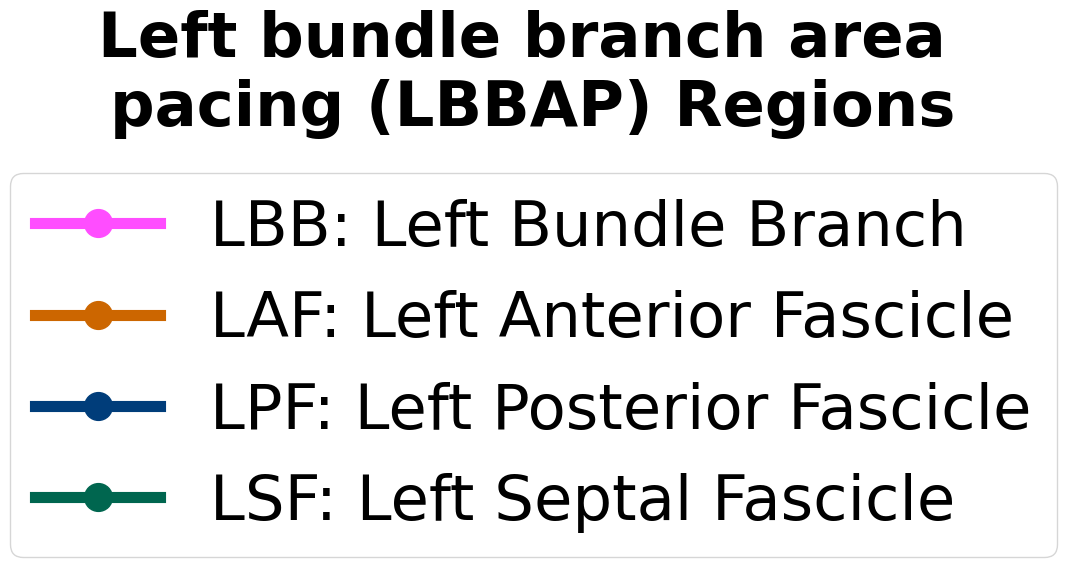

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def make_legend_box(fontsize=45): 
    if fontsize==45: 
        y_offset=-0.8
    elif fontsize==30: 
        y_offset=-0.2
    else: 
        y_offset=-0.1

    # Combined dictionary: {id: (name, color)}
    regions = {
        20: ('LBB: Left Bundle Branch', "#FF4DFF"),
        21: ('LAF: Left Anterior Fascicle', '#cc6600'),
        22: ('LPF: Left Posterior Fascicle', "#003d7a"),
        23: ('LSF: Left Septal Fascicle', "#00664f")
    }

    # Create legend handles (solid line + circle marker)
    legend_elements = [
        Line2D([0], [0], color=color, lw=8, marker='o', markersize=20, linestyle='-', label=name)
        for name, color in regions.values()
    ]

    # Create a figure for the legend only
    fig = plt.figure(figsize=(4, 2))

    # Add the legend to the figure
    # Add a bold figure title
    fig.suptitle(
        "Left bundle branch area \npacing (LBBAP) Regions",
        fontsize=fontsize,
        fontweight='bold',
        color='black'
    )
    fig.legend(
        handles=legend_elements,
        loc='center',
        bbox_to_anchor=(0.5, y_offset),    # move legend down (0.45 = 45% up from bottom) 
        ncol=1,
        frameon=True,
        fontsize=fontsize)

    # Hide axes
    plt.axis('off')
    plt.subplots_adjust(top=0.85)
    # Save or show
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    plt.savefig(f'{output_plot_path}/legend_only.png', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    # For figure 5 plots legend
    #make_legend_box(45)

    # For Figure 1, small plot 
    make_legend_box(45)
